# Review of `template_coadd_analysis` outputs

Reviews one output RUN of `template_coadd_analysis.sh` (pipeline
`template_coadd_analysis.yaml`, subset `template_coadd_qa`) together with the template
collection it was run on.

1. **Execution status**: quanta done / no-work / failed per task, against what the input
   collection implies, so partial (e.g. timed-out) runs are obvious.
2. **n_image depth**: per-tract depth metrics per band. Includes a check for, and recovery
   of, bands hidden by chained-collection shadowing (see below).
3. **Mask fractions**: per-tract NO_DATA / CLIPPED / DETECTED / NOT_DEBLENDED fractions.
4. **Interpolated pixels**: per-patch `interpolated_pixel_count` from `assembleTemplateCoadd`.
5. **Plots**: the whole-sky plots and the per-tract n_image depth plots.
6. **Coverage gaps**: tracts with templates but missing QA, and a summary of flagged tracts.

Every section works on a partial run. When a survey-level table hasn't been written yet,
the section falls back to reading the per-tract/per-patch metric bundles directly, or
says what is missing.

**Chained-collection shadowing.** `template_coadd_depth_summary_metrics` (written upstream
by each band's template RUN) has dimensions {skymap, tract}, with no band. In a CHAINED input such
as `bestSeeing_wide_gri`, a tract present in several band RUNs resolves to the *first*
RUN only, so `coadd_depth_summary_metrics_table_template` silently lacks the other bands
for those tracts. Section 2 measures the loss and, with `RECOVER_SHADOWED_DEPTH = True`,
rebuilds the depth metrics from each child RUN separately.

## Parameters

In [1]:
REPO = "/shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres"

# Output RUN of template_coadd_analysis.sh. None picks the newest RUN under ANALYSIS_ROOT.
ANALYSIS_RUN = "DECam/templates/analysis/bestSeeing_wide_gri/20261110T235625Z"
ANALYSIS_ROOT = "DECam/templates/analysis"

# Template collection the run used (its INPUT_COLLECTION). RUN or CHAINED.
INPUT_COLLECTION = "DECam/templates/bestSeeing_wide_gri"
SKYMAP = "decam_rings_v1"
SKYMAP_COLLECTION = "skymaps"

# Bands to review. None uses every band with template_coadd in INPUT_COLLECTION.
BANDS = ['g','r','i']

# Rebuild per-band depth metrics from each child RUN of a CHAINED input (Section 2).
RECOVER_SHADOWED_DEPTH = True

# Fallbacks when a survey-level table is not in ANALYSIS_RUN yet: read the per-tract /
# per-patch metric bundles instead. Patch-level metadata bundles are many (~60k for gri);
# MAX_BUNDLES caps how many are read per band for a quick look (None = all).
FALLBACK_TO_BUNDLES = True
MAX_BUNDLES = None

# Thresholds used to flag tracts/patches in the summary.
MIN_FRAC_DEPTH_GE_1 = 50.0       # % of tract pixels with any template (n_image >= 1, mean over patches)
MAX_NO_DATA_FRACTION = 0.5       # mean NO_DATA fraction over the tract's patches
MAX_INTERP_FRACTION = 0.01       # interpolated pixels / patch pixels

N_WORST = 10                     # rows shown in "worst" tables
SHOW_DEPTH_PLOT_TRACTS = None    # e.g. [4250, 5230]; None shows the N_WORST shallowest tracts

## Setup

In [2]:
import re
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from lsst.daf.butler import Butler, CollectionType

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)

butler = Butler(REPO, writeable=False)

if ANALYSIS_RUN is None:
    runs = sorted(butler.collections.query(f"{ANALYSIS_ROOT}/*", collection_types={CollectionType.RUN}))
    if not runs:
        raise RuntimeError(f"No RUN collections under {ANALYSIS_ROOT}/")
    # Output RUNs end in a UTC timestamp; take the newest.
    ANALYSIS_RUN = max(runs, key=lambda r: r.rsplit("/", 1)[-1])

info = butler.collections.get_info(INPUT_COLLECTION)
INPUT_RUNS = list(info.children) if info.type == CollectionType.CHAINED else [INPUT_COLLECTION]

skymap = butler.get("skyMap", skymap=SKYMAP, collections=SKYMAP_COLLECTION)

print("analysis RUN :", ANALYSIS_RUN)
print("input        :", INPUT_COLLECTION, f"({info.type.name})")
for r in INPUT_RUNS:
    print("   ", r)

analysis RUN : DECam/templates/analysis/bestSeeing_wide_gri/20261110T235625Z
input        : DECam/templates/bestSeeing_wide_gri (CHAINED)
    DECam/templates/bestSeeing_wide/g/20261027T133747Z
    DECam/templates/bestSeeing_wide/r/20261027T140603Z
    DECam/templates/bestSeeing_wide/i/20261029T132629Z


In [3]:
def count(dataset_type, collections, **where):
    """Number of datasets of a type (0 if the type is not registered)."""
    try:
        with butler.query() as q:
            x = q.datasets(dataset_type, collections=collections)
            if where:
                x = x.where(skymap=SKYMAP, **where)
            return x.count(exact=True)
    except Exception:
        return 0


def refs(dataset_type, collections, find_first=True):
    """All refs of a type in the collections ([] if unregistered)."""
    try:
        return list(butler.query_datasets(dataset_type, collections=collections, limit=None,
                                          find_first=find_first, explain=False))
    except Exception:
        return []


def data_ids(dataset_type, collections, keys):
    """Set of data-ID tuples (in ``keys`` order) of a dataset type."""
    return {tuple(r.dataId[k] for k in keys) for r in refs(dataset_type, collections)}


def bundle_values(ref):
    """{"<atool>_<metric>": value} from a MetricMeasurementBundle."""
    out = {}
    for atool, measurements in butler.get(ref).items():
        for m in measurements:
            name = getattr(m.metric_name, "metric", m.metric_name)
            out[f"{atool}_{name}"] = m.quantity.value
    return out


def bundles_to_frame(ref_list, keys, max_n=None):
    """DataFrame of bundle metrics, one row per ref, with the data-ID keys as columns."""
    rows = []
    for r in ref_list[:max_n] if max_n else ref_list:
        row = {k: r.dataId[k] for k in keys}
        row.update(bundle_values(r))
        rows.append(row)
    return pd.DataFrame(rows)


def table_to_frame(table):
    """Astropy metric table -> DataFrame, dropping the (unhashable) corners column."""
    cols = [c for c in table.colnames if c != "corners"]
    return table[cols].to_pandas()


def tract_center(tract):
    c = skymap[int(tract)].ctr_coord
    return c.getRa().asDegrees(), c.getDec().asDegrees()


def add_centers(df):
    if len(df):
        ra, dec = zip(*(tract_center(t) for t in df["tract"]))
        df = df.assign(ra=ra, dec=dec)
    return df


def show_png(ref, width=None):
    display(Image(data=butler.getURI(ref).read(), width=width))


def sky_scatter(ax, df, column, label, cmap="viridis", vmin=None, vmax=None):
    """Mollweide scatter of tract centres coloured by ``column`` (RA increasing to the left)."""
    ra = np.radians(-((np.asarray(df["ra"]) + 180) % 360 - 180))
    sc = ax.scatter(ra, np.radians(df["dec"]), c=df[column], s=6, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.grid(True, alpha=0.3)
    ax.set_xticklabels([])
    plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.05, shrink=0.8, label=label)

In [4]:
# Bands and tracts that have templates in the input.
tmpl = defaultdict(set)          # band -> {tract}
tmpl_patches = defaultdict(int)  # band -> number of patches
for r in refs("template_coadd", INPUT_COLLECTION):
    tmpl[r.dataId["band"]].add(r.dataId["tract"])
    tmpl_patches[r.dataId["band"]] += 1
if BANDS is None:
    BANDS = [b for b in "ugrizy" if b in tmpl] + sorted(set(tmpl) - set("ugrizy"))
display(pd.DataFrame({"tracts": {b: len(tmpl[b]) for b in BANDS},
                      "patches": {b: tmpl_patches[b] for b in BANDS}}).T)

,g,r,i
tracts,586,751,938
patches,15670,19121,25782


## 1. Execution status

For each task: quanta with a `_metadata` dataset finished (including NoWorkFound
quanta), quanta with a `_log` but no `_metadata` failed, and the remainder to the expected
count were never attempted (e.g. the job timed out). "outputs" counts the task's main
product. Finished quanta without it ended with NoWorkFound.

In [5]:
all_template_tracts = set().union(*tmpl.values())
expected = {
    "analyzeAssembleTemplateCoaddMetadataTemplate":
        sum(count("assembleTemplateCoadd_metadata", INPUT_COLLECTION, band=b) for b in BANDS),
    "coaddDepthPlotTemplate": len(all_template_tracts),
    "makeCoaddDepthMetricTableTemplate": 1,
    "coaddDepthWholeSkyPlotTemplate": 1,
    "makeMaskFractionMetricTableTemplate": len(BANDS),
    "maskFractionWholeSkyPlotTemplate": len(BANDS),
    "makeAssembleMetadataMetricTableTemplate": len(BANDS),
}
main_output = {
    "analyzeAssembleTemplateCoaddMetadataTemplate": "assembleTemplateCoadd_metadata_template_metrics",
    "coaddDepthPlotTemplate": "coadd_depth_template_n_image_CoaddDepthPlot",
    "makeCoaddDepthMetricTableTemplate": "coadd_depth_summary_metrics_table_template",
    "coaddDepthWholeSkyPlotTemplate": "coadd_depth_template_coadd_depth_summary_metrics_depth_above_threshold_1_mean_WholeSkyPlot",
    "makeMaskFractionMetricTableTemplate": "coadd_tract_mask_fraction_metrics_table_template",
    "maskFractionWholeSkyPlotTemplate": "coadd_mask_fraction_template_NO_DATA_fraction_mean_WholeSkyPlot",
    "makeAssembleMetadataMetricTableTemplate": "assembleTemplateCoadd_metadata_metrics_table_template",
}
rows = []
for task, n_exp in expected.items():
    n_meta = count(f"{task}_metadata", ANALYSIS_RUN)
    n_log = count(f"{task}_log", ANALYSIS_RUN)
    rows.append(dict(task=task, expected=n_exp, finished=n_meta, failed=max(n_log - n_meta, 0),
                     not_attempted=max(n_exp - n_log, 0),
                     outputs=count(main_output[task], ANALYSIS_RUN)))
status = pd.DataFrame(rows).set_index("task")
status["no_work"] = status["finished"] - status["outputs"]
status["done_%"] = (100 * status["finished"] / status["expected"]).round(1)
display(status)

RUN_COMPLETE = bool((status["not_attempted"] == 0).all() and (status["failed"] == 0).all())
if not RUN_COMPLETE:
    display(Markdown(
        "**Run incomplete.** Sections below use what exists. To finish, rerun the same "
        "pipeline into this RUN with `--extend-run --skip-existing-in` it (or start a new RUN)."))

,expected,finished,failed,not_attempted,outputs,no_work,done_%
task,,,,,,,
analyzeAssembleTemplateCoaddMetadataTemplate,62009,62009,0,0,60621,1388,100.0
coaddDepthPlotTemplate,1051,1051,0,0,1051,0,100.0
makeCoaddDepthMetricTableTemplate,1,1,0,0,1,0,100.0
coaddDepthWholeSkyPlotTemplate,1,1,0,0,3,-2,100.0
makeMaskFractionMetricTableTemplate,3,3,0,0,3,0,100.0
maskFractionWholeSkyPlotTemplate,3,3,0,0,3,0,100.0
makeAssembleMetadataMetricTableTemplate,3,3,0,0,3,0,100.0


In [6]:
# Failed quanta, if any: the last ERROR line of each failed quantum's log.
failed_rows = []
for task in status.index[status["failed"] > 0]:
    meta = {r.dataId for r in refs(f"{task}_metadata", ANALYSIS_RUN)}
    for r in refs(f"{task}_log", ANALYSIS_RUN):
        if r.dataId in meta:
            continue
        errs = [rec.message for rec in butler.get(r) if rec.levelname in ("ERROR", "CRITICAL")]
        failed_rows.append(dict(task=task, dataId=str(r.dataId.mapping),
                                error=(errs[-1][:200] if errs else "")))
display(pd.DataFrame(failed_rows) if failed_rows else Markdown("No failed quanta."))

No failed quanta.

## 2. n_image depth

Columns are `coadd_depth_summary_metrics_<stat>_<band>_<agg>`:

- `stat` is `depth_above_threshold_N` (% of a patch's pixels with n_image >= N, for N in
  1, 2, 3, 5, 12) or `depth_P_percentile` (n_image at percentile P).
- `agg` (`mean`, `median`, `stdev`) aggregates the stat over the tract's patches.

In [7]:
DEPTH_PREFIX = "coadd_depth_summary_metrics_"
depth_ref = refs("coadd_depth_summary_metrics_table_template", ANALYSIS_RUN)
depth_table = table_to_frame(butler.get(depth_ref[0])) if depth_ref else pd.DataFrame()
print("depth table rows (tracts):", len(depth_table) if depth_ref else "table not written yet")


def depth_long(wide):
    """Wide depth table -> long frame: tract, band, + one column per '<stat>_<agg>'."""
    out = []
    for band in BANDS:
        pat = re.compile(rf"^{DEPTH_PREFIX}(.+)_{band}_(mean|median|stdev)$")
        cols = {c: f"{m.group(1)}_{m.group(2)}" for c in wide.columns if (m := pat.match(c))}
        sub = wide[["tract", *cols]].rename(columns=cols)
        sub = sub[np.isfinite(sub.get("depth_above_threshold_1_mean", np.nan))]
        out.append(sub.assign(band=band))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()


depth = depth_long(depth_table) if len(depth_table) else pd.DataFrame(columns=["tract", "band"])

# Shadowing check: tracts per band in the table vs upstream bundles per band RUN.
upstream_depth = {}   # band -> {tract: ref}, from the child RUN holding that band
for run in INPUT_RUNS:
    rs = refs("template_coadd_depth_summary_metrics", run)
    run_bands = {r.dataId["band"] for r in refs("template_coadd", run)[:50]}
    for band in run_bands & set(BANDS):
        upstream_depth.setdefault(band, {}).update({r.dataId["tract"]: r for r in rs})
shadow = pd.DataFrame({
    "upstream_tracts": {b: len(upstream_depth.get(b, {})) for b in BANDS},
    "in_table": {b: int((depth["band"] == b).sum()) for b in BANDS},
})
shadow["hidden"] = shadow["upstream_tracts"] - shadow["in_table"]
display(shadow)

depth table rows (tracts): 1048


,upstream_tracts,in_table,hidden
g,542,542,0
r,709,429,280
i,938,77,861


In [8]:
# Recover hidden bands by reading each band RUN's tract bundles directly.
if RECOVER_SHADOWED_DEPTH and (shadow["hidden"] > 0).any():
    have = set(zip(depth["tract"], depth["band"]))
    rows = []
    for band, by_tract in upstream_depth.items():
        todo = [r for t, r in sorted(by_tract.items()) if (t, band) not in have]
        if MAX_BUNDLES:
            todo = todo[:MAX_BUNDLES]
        for r in todo:
            vals = bundle_values(r)
            pat = re.compile(rf"^{DEPTH_PREFIX}(.+)_{band}_(mean|median|stdev)$")
            row = {f"{m.group(1)}_{m.group(2)}": v for k, v in vals.items() if (m := pat.match(k))}
            rows.append(dict(tract=r.dataId["tract"], band=band, **row))
    recovered = pd.DataFrame(rows)
    print(f"recovered {len(recovered)} (tract, band) rows from the band RUNs")
    depth = pd.concat([depth, recovered], ignore_index=True)
depth = add_centers(depth)
display(depth.groupby("band")[["depth_above_threshold_1_mean", "depth_above_threshold_3_mean",
                               "depth_above_threshold_5_mean", "depth_50_percentile_median"]]
        .describe().T.round(2))

recovered 1141 (tract, band) rows from the band RUNs


band                                     g       i       r
depth_above_threshold_1_mean count  542.00  938.00  709.00
                             mean    71.45   76.07   71.17
                             std     26.14   24.46   26.30
                             min      0.00    0.00    0.57
                             25%     56.69   62.14   53.92
                             50%     79.57   87.02   77.06
                             75%     93.51   95.54   95.39
                             max     98.94   99.29   99.33
depth_above_threshold_3_mean count  542.00  938.00  709.00
                             mean    19.34   33.09   29.31
                             std     19.98   24.07   25.04
                             min      0.00    0.00    0.00
                             25%      0.29    6.92    1.29
                             50%     13.84   36.16   27.27
                             75%     33.79   56.23   55.19
                             max     72.57   74.20   76.35
depth_above_threshold_5_mean count  542.00  938.00  709.00
                             mean     1.69    5.02    4.22
                             std      4.68    7.09    7.08
                             min      0.00    0.00    0.00
                             25%      0.00    0.00    0.00
                             50%      0.00    2.22    0.92
                             75%      0.87    7.62    5.98
                             max     40.04   45.87   54.50
depth_50_percentile_median   count  542.00  938.00  709.00
                             mean     1.50    1.95    1.77
                             std      0.98    1.14    1.19
                             min      0.00    0.00    0.00
                             25%      1.00    1.00    1.00
                             50%      2.00    2.00    2.00
                             75%      2.00    3.00    3.00
                             max      4.00    5.00    5.00

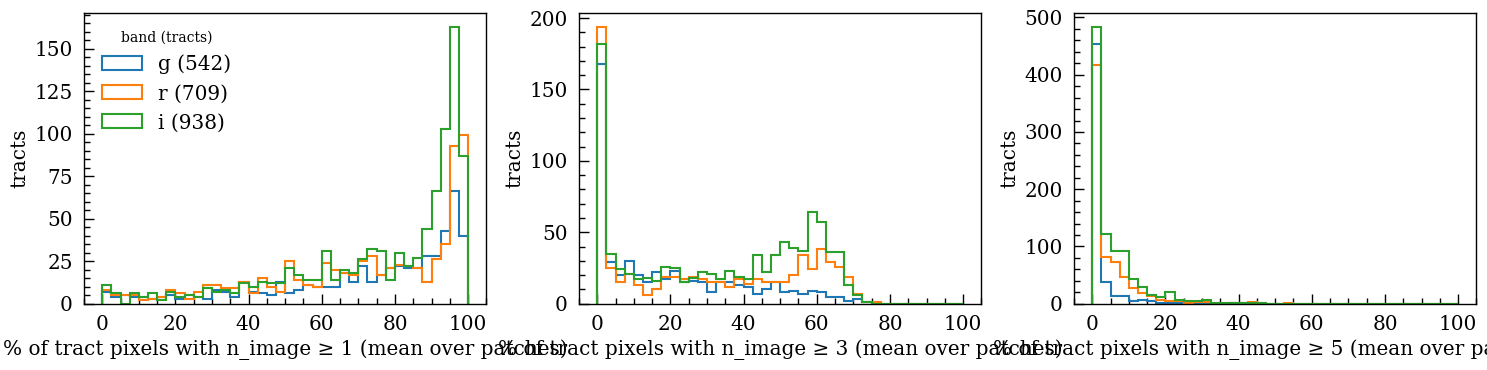

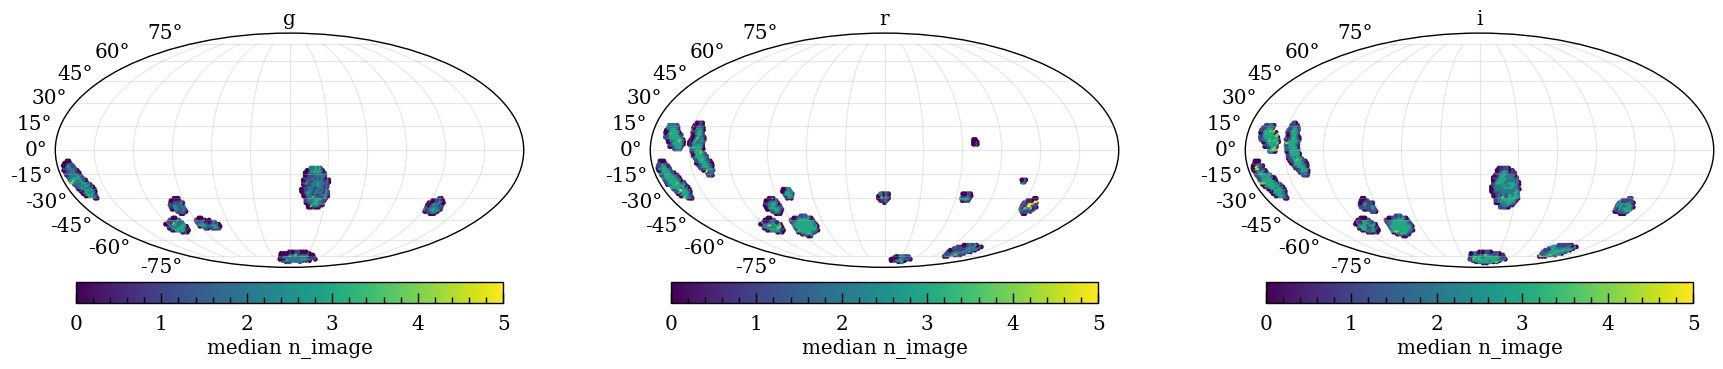

In [9]:
if len(depth):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, n in zip(axes, [1, 3, 5]):
        for band in BANDS:
            v = depth.loc[depth["band"] == band, f"depth_above_threshold_{n}_mean"].dropna()
            ax.hist(v, bins=np.linspace(0, 100, 41), histtype="step", lw=1.5, label=f"{band} ({len(v)})")
        ax.set_xlabel(f"% of tract pixels with n_image ≥ {n} (mean over patches)")
        ax.set_ylabel("tracts")
    axes[0].legend(title="band (tracts)")
    fig.tight_layout()

    fig = plt.figure(figsize=(6 * len(BANDS), 3.6))
    for i, band in enumerate(BANDS):
        ax = fig.add_subplot(1, len(BANDS), i + 1, projection="mollweide")
        sub = depth[depth["band"] == band]
        if len(sub):
            sky_scatter(ax, sub, "depth_50_percentile_median", "median n_image", vmin=0, vmax=5)
        ax.set_title(band)
    fig.tight_layout()

In [10]:
shallow = (depth.sort_values("depth_above_threshold_3_mean")
           .groupby("band").head(N_WORST)
           [["band", "tract", "depth_above_threshold_1_mean", "depth_above_threshold_3_mean",
             "depth_50_percentile_median", "ra", "dec"]].round(2))
display(Markdown(f"**Shallowest {N_WORST} tracts per band** (lowest % with n_image ≥ 3)"))
display(shallow)

**Shallowest 10 tracts per band** (lowest % with n_image ≥ 3)

,band,tract,depth_above_threshold_1_mean,depth_above_threshold_3_mean,depth_50_percentile_median,ra,dec
1653,i,4052,52.66,0.0,1.0,103.88,-34.96
759,r,7635,50.73,0.0,1.0,143.10,-11.16
1693,i,4455,61.13,0.0,1.0,97.39,-31.98
1692,i,4454,54.32,0.0,1.0,95.65,-31.98
1691,i,4391,4.90,0.0,0.0,345.88,-33.47
1675,i,4324,38.34,0.0,0.0,227.65,-33.47
1674,i,4253,45.62,0.0,0.0,102.35,-33.47
743,r,6939,21.14,0.0,0.0,163.08,-15.62
779,r,8349,1.04,0.0,0.0,134.44,-6.69
778,r,8116,26.05,0.0,0.0,145.50,-8.18


## 3. Mask fractions

From `coadd_tract_mask_fraction_metrics_table_template`, falling back to the upstream
`template_coadd_tract_mask_fraction_metrics` bundles.

- Columns are `full_tract_<agg>_<PLANE>_fraction` (over all patch pixels) and
  `full_tract_<agg>_<PLANE>_valid_data_fraction` (over non-NO_DATA pixels only).
- `agg` is `min`, `max`, `mean` or `ct` over the tract's patches.

In [11]:
mask_frames = []
for band in BANDS:
    t = refs("coadd_tract_mask_fraction_metrics_table_template", ANALYSIS_RUN)
    t = [r for r in t if r.dataId["band"] == band]
    if t:
        mask_frames.append(table_to_frame(butler.get(t[0])).assign(band=band, source="table"))
    elif FALLBACK_TO_BUNDLES:
        bs = [r for r in refs("template_coadd_tract_mask_fraction_metrics", INPUT_COLLECTION)
              if r.dataId["band"] == band]
        if bs:
            mask_frames.append(bundles_to_frame(bs, ["tract"], MAX_BUNDLES).assign(band=band, source="bundles"))
mask = add_centers(pd.concat(mask_frames, ignore_index=True)) if mask_frames else pd.DataFrame()
if len(mask):
    display(mask.groupby(["band", "source"]).size().rename("tracts").to_frame())
else:
    display(Markdown("No mask-fraction table or bundles found."))

MASK_COLS = {
    "NO_DATA": "full_tract_mean_NO_DATA_fraction",
    "CLIPPED": "full_tract_mean_CLIPPED_valid_data_fraction",
    "DETECTED": "full_tract_mean_DETECTED_valid_data_fraction",
    "SAT": "full_tract_mean_SAT_valid_data_fraction",
    "INTRP": "full_tract_mean_INTRP_valid_data_fraction",
    "NOT_DEBLENDED": "full_tract_mean_NOT_DEBLENDED_valid_data_fraction",
}
MASK_COLS = {k: v for k, v in MASK_COLS.items() if v in mask.columns}
if len(mask):
    display(mask.groupby("band")[list(MASK_COLS.values())].median().rename(columns={v: k for k, v in MASK_COLS.items()}).round(4)
            .style.set_caption("median over tracts of the mean per-patch fraction"))

,,tracts
band,source,
g,table,542
i,table,938
r,table,709


,NO_DATA,CLIPPED,DETECTED,SAT,INTRP,NOT_DEBLENDED
band,,,,,,
g,0.224500,0.000900,0.157400,0.001300,0.010700,0.000000
i,0.159900,0.001900,0.198600,0.003400,0.013500,0.000000
r,0.251800,0.001700,0.209500,0.002700,0.010000,0.000000


**Tracts with the largest mean NO_DATA fraction (top 10 per band)**

,band,tract,NO_DATA,CLIPPED,DETECTED,SAT,INTRP,NOT_DEBLENDED,ra,dec
155,g,2913,1.0000,NaN,NaN,NaN,NaN,NaN,83.3898,-43.8843
1355,i,610,1.0000,NaN,NaN,NaN,NaN,NaN,342.8571,-70.6612
55,g,455,0.9999,0.0000,1.0000,0.0000,0.0000,0.0,13.8462,-72.1488
1273,i,246,0.9964,0.0000,0.3735,0.1059,0.0147,0.0,305.6604,-78.0992
549,r,246,0.9956,0.0000,0.3170,0.0000,0.0217,0.0,305.6604,-78.0992
16,g,246,0.9954,0.0000,0.2762,0.0000,0.0087,0.0,305.6604,-78.0992
888,r,4988,0.9939,0.0000,0.7461,0.0000,0.0156,0.0,287.6636,-29.0083
203,g,3981,0.9937,0.0000,0.0881,0.0000,0.0102,0.0,336.2437,-36.4463
1977,i,8108,0.9905,0.0000,0.1804,0.0000,0.0118,0.0,133.5000,-8.1818
1057,r,8349,0.9898,0.0000,0.1226,0.0000,0.0016,0.0,134.4398,-6.6942


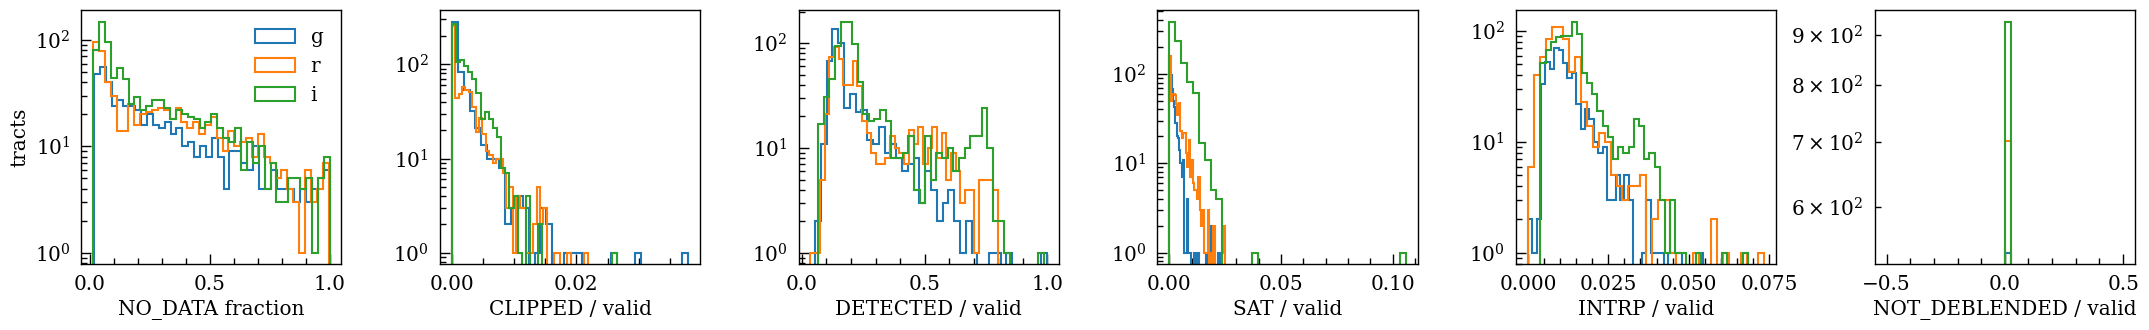

In [12]:
if len(mask) and MASK_COLS:
    fig, axes = plt.subplots(1, len(MASK_COLS), figsize=(3.6 * len(MASK_COLS), 3.4))
    for ax, (plane, col) in zip(np.atleast_1d(axes), MASK_COLS.items()):
        for band in BANDS:
            v = mask.loc[mask["band"] == band, col].dropna()
            if len(v):
                ax.hist(v, bins=40, histtype="step", lw=1.5, label=band)
        ax.set_xlabel(plane + (" fraction" if plane == "NO_DATA" else " / valid"))
        ax.set_yscale("log")
    np.atleast_1d(axes)[0].legend()
    np.atleast_1d(axes)[0].set_ylabel("tracts")
    fig.tight_layout()

    if "NO_DATA" in MASK_COLS:
        display(Markdown(f"**Tracts with the largest mean NO_DATA fraction (top {N_WORST} per band)**"))
        display(mask.sort_values(MASK_COLS["NO_DATA"], ascending=False).groupby("band").head(N_WORST)
                [["band", "tract", *MASK_COLS.values(), "ra", "dec"]]
                .rename(columns={v: k for k, v in MASK_COLS.items()}).round(4))

## 4. Interpolated pixels (`assembleTemplateCoadd:interpImage`)

`interpolated_pixel_count` per patch, from
`assembleTemplateCoadd_metadata_metrics_table_template` or, before that exists, from the
per-patch `assembleTemplateCoadd_metadata_template_metrics` bundles. The fraction is
relative to the patch's outer bounding box.

In [13]:
METRIC = "assembleTemplateCoaddMetadata_interpolated_pixel_count"
interp_frames = []
for band in BANDS:
    t = [r for r in refs("assembleTemplateCoadd_metadata_metrics_table_template", ANALYSIS_RUN)
         if r.dataId["band"] == band]
    if t:
        interp_frames.append(table_to_frame(butler.get(t[0])).assign(band=band, source="table"))
    elif FALLBACK_TO_BUNDLES:
        bs = [r for r in refs("assembleTemplateCoadd_metadata_template_metrics", ANALYSIS_RUN)
              if r.dataId["band"] == band]
        if bs:
            print(f"{band}: reading {len(bs) if not MAX_BUNDLES else min(len(bs), MAX_BUNDLES)} bundles ...")
            interp_frames.append(bundles_to_frame(bs, ["tract", "patch"], MAX_BUNDLES)
                                 .assign(band=band, source="bundles"))
interp = pd.concat(interp_frames, ignore_index=True) if interp_frames else pd.DataFrame()
if len(interp):
    area = {}
    def patch_area(tract, patch):
        key = (tract, patch)
        if key not in area:
            area[key] = skymap[int(tract)][int(patch)].getOuterBBox().getArea()
        return area[key]
    interp["interp_fraction"] = [v / patch_area(t, p) for t, p, v in
                                 zip(interp["tract"], interp["patch"], interp[METRIC])]
    display(interp.groupby(["band", "source"])["interp_fraction"]
            .describe(percentiles=[0.5, 0.9, 0.99]).round(5))
else:
    display(Markdown("No interpolated-pixel metrics found."))

,,count,mean,std,min,50%,90%,99%,max
band,source,,,,,,,,
g,table,15670.0,0.00021,0.00019,0.0,0.00016,0.00043,0.00094,0.00196
i,table,25782.0,0.00043,0.00049,0.0,0.00025,0.00110,0.00230,0.00527
r,table,19121.0,0.00041,0.00049,0.0,0.00023,0.00101,0.00237,0.00353


**Patches with the largest interpolated fraction (top 10 per band)**

,band,tract,patch,assembleTemplateCoaddMetadata_interpolated_pixel_count,interp_fraction
38660,i,973,17,90784.0,0.00527
38630,i,972,12,90067.0,0.00523
38631,i,972,13,90362.0,0.00512
38636,i,972,18,85011.0,0.00494
38625,i,972,7,86365.0,0.00490
38666,i,973,23,83662.0,0.00486
38659,i,973,16,79236.0,0.00449
38626,i,972,8,79214.0,0.00449
38654,i,973,11,76859.0,0.00446
38624,i,972,6,76681.0,0.00445


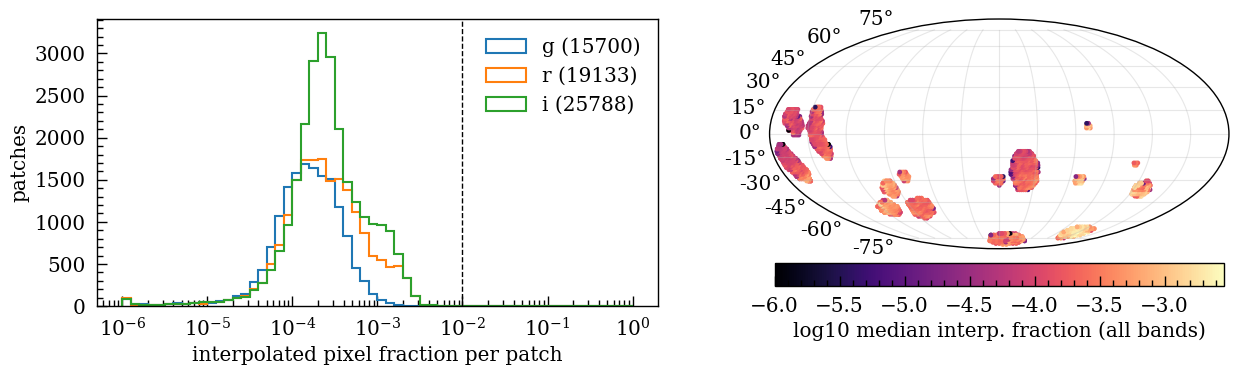

In [14]:
if len(interp):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    bins = np.logspace(-6, 0, 61)
    for band in BANDS:
        v = interp.loc[interp["band"] == band, "interp_fraction"]
        axes[0].hist(v.clip(lower=1e-6), bins=bins, histtype="step", lw=1.5, label=f"{band} ({len(v)})")
    axes[0].set_xscale("log"); axes[0].set_xlabel("interpolated pixel fraction per patch")
    axes[0].axvline(MAX_INTERP_FRACTION, color="k", ls="--", lw=1)
    axes[0].set_ylabel("patches"); axes[0].legend()

    per_tract = (interp.groupby(["band", "tract"])["interp_fraction"].median()
                 .reset_index().pipe(add_centers))
    ax = fig.add_subplot(1, 2, 2, projection="mollweide"); axes[1].remove()
    sky_scatter(ax, per_tract.assign(lf=np.log10(per_tract["interp_fraction"].clip(lower=1e-6))),
                "lf", "log10 median interp. fraction (all bands)", cmap="magma")
    fig.tight_layout()

    display(Markdown(f"**Patches with the largest interpolated fraction (top {N_WORST} per band)**"))
    display(interp.sort_values("interp_fraction", ascending=False).groupby("band").head(N_WORST)
            [["band", "tract", "patch", METRIC, "interp_fraction"]].round(5))

## 5. Plots

### Whole-sky plots

In [18]:
ws_types

['coadd_depth_template_coadd_depth_summary_metrics_depth_above_threshold_12_mean_WholeSkyPlot',
 'coadd_depth_template_coadd_depth_summary_metrics_depth_above_threshold_1_mean_WholeSkyPlot',
 'coadd_depth_template_coadd_depth_summary_metrics_depth_above_threshold_2_mean_WholeSkyPlot',
 'coadd_depth_template_coadd_depth_summary_metrics_depth_above_threshold_3_mean_WholeSkyPlot',
 'coadd_depth_template_coadd_depth_summary_metrics_depth_above_threshold_5_mean_WholeSkyPlot',
 'coadd_mask_fraction_template_CLIPPED_fraction_mean_WholeSkyPlot',
 'coadd_mask_fraction_template_DETECTED_fraction_mean_WholeSkyPlot',
 'coadd_mask_fraction_template_NOT_DEBLENDED_fraction_mean_WholeSkyPlot',
 'coadd_mask_fraction_template_NO_DATA_fraction_mean_WholeSkyPlot']

`coadd_mask_fraction_template_NO_DATA_fraction_mean_WholeSkyPlot` {'band': 'g', 'skymap': 'decam_rings_v1'}

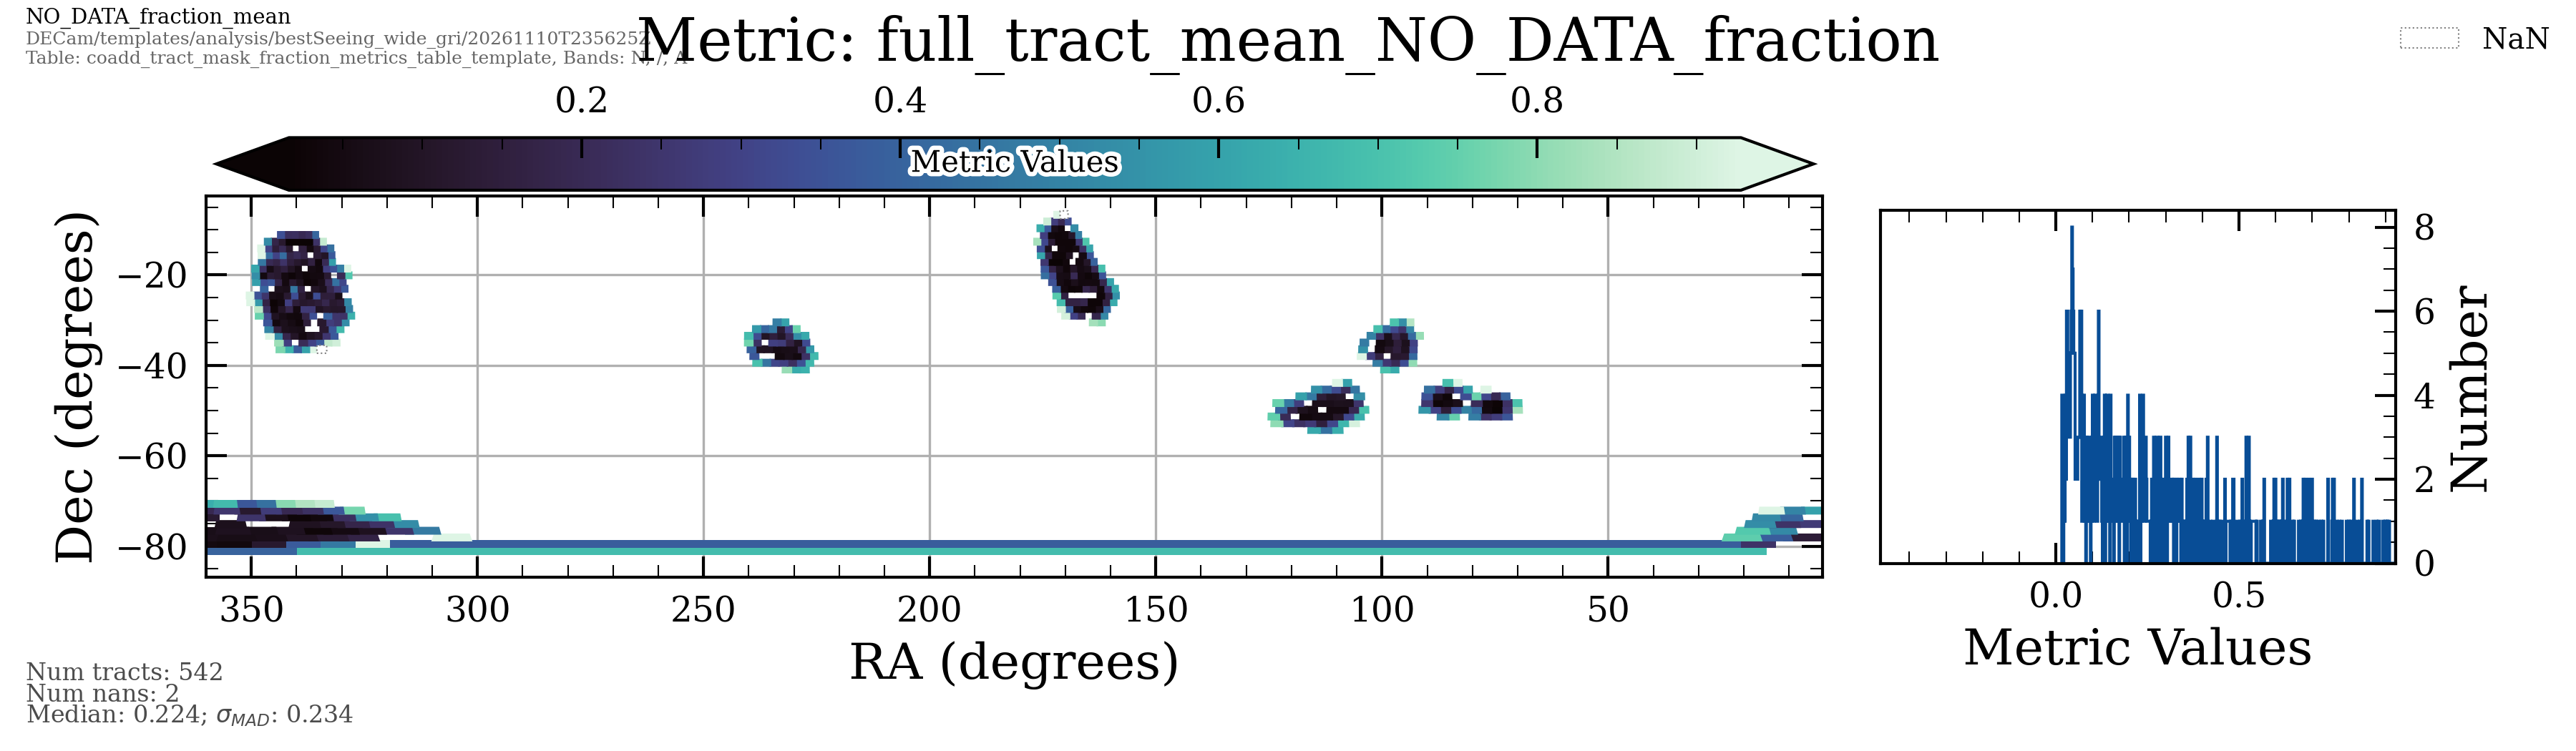

`coadd_mask_fraction_template_NO_DATA_fraction_mean_WholeSkyPlot` {'band': 'i', 'skymap': 'decam_rings_v1'}

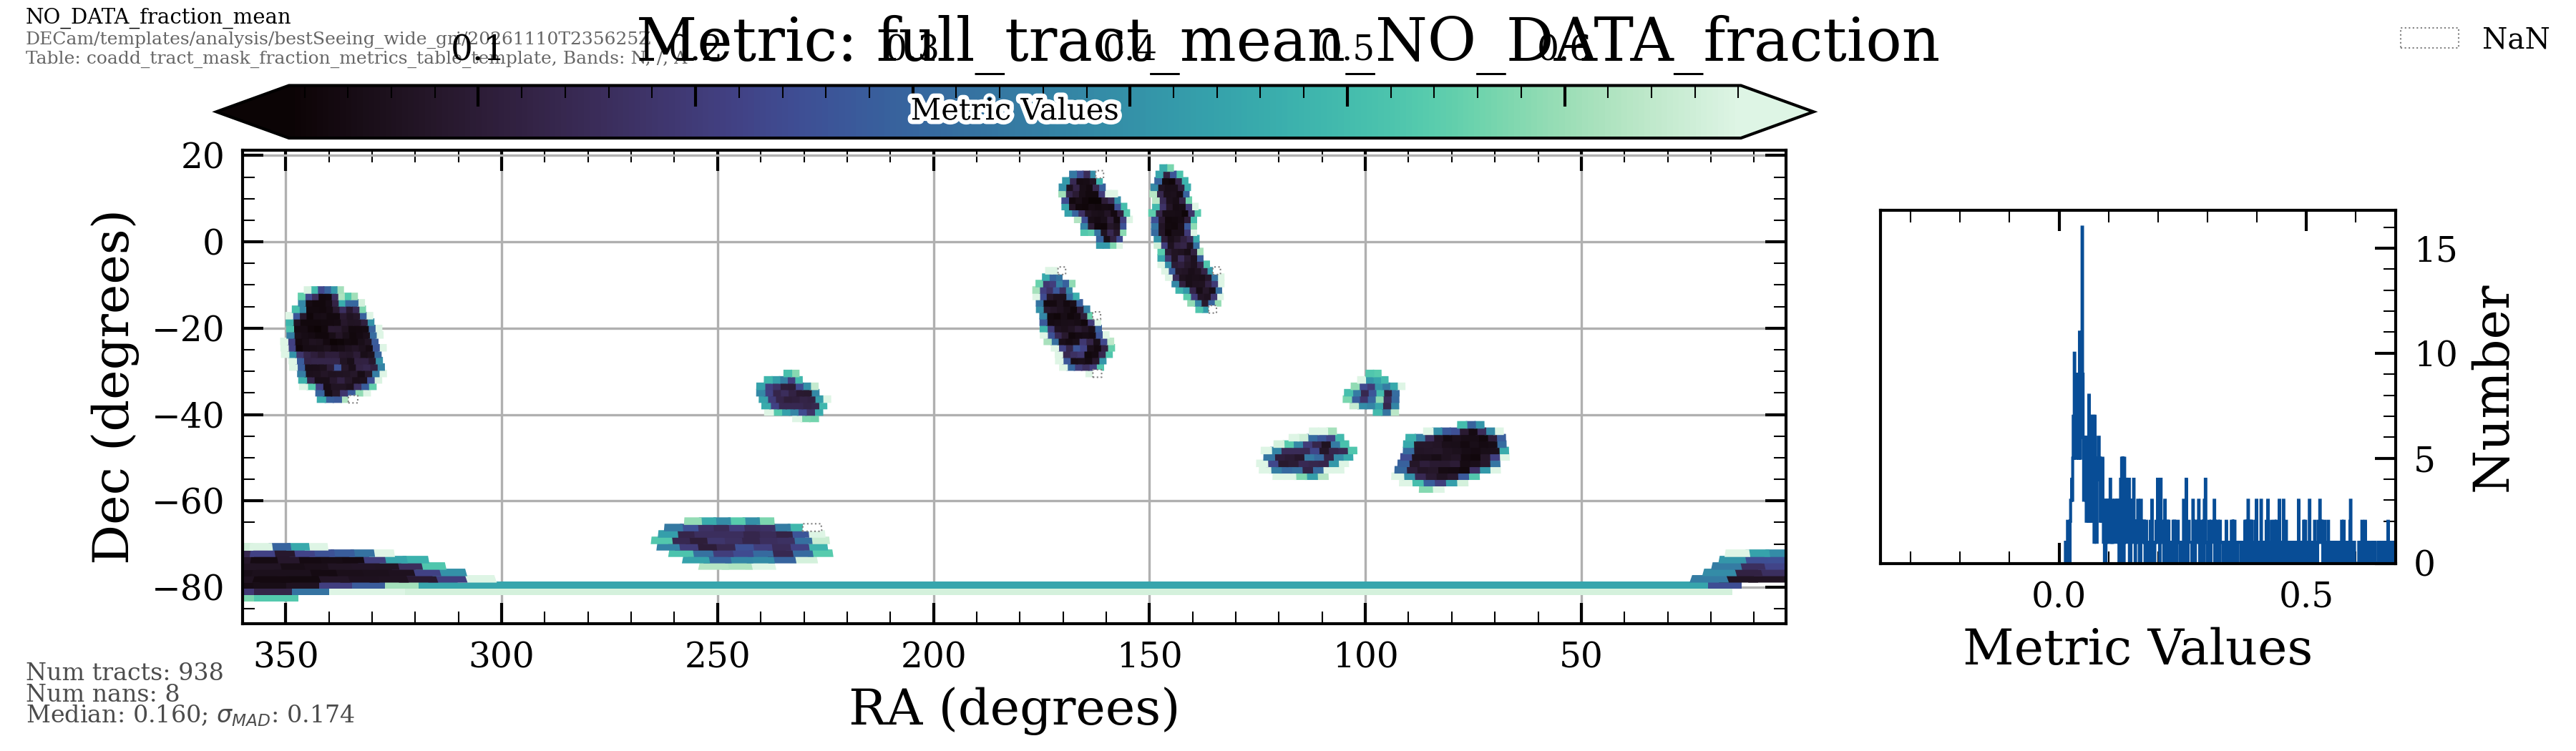

`coadd_mask_fraction_template_NO_DATA_fraction_mean_WholeSkyPlot` {'band': 'r', 'skymap': 'decam_rings_v1'}

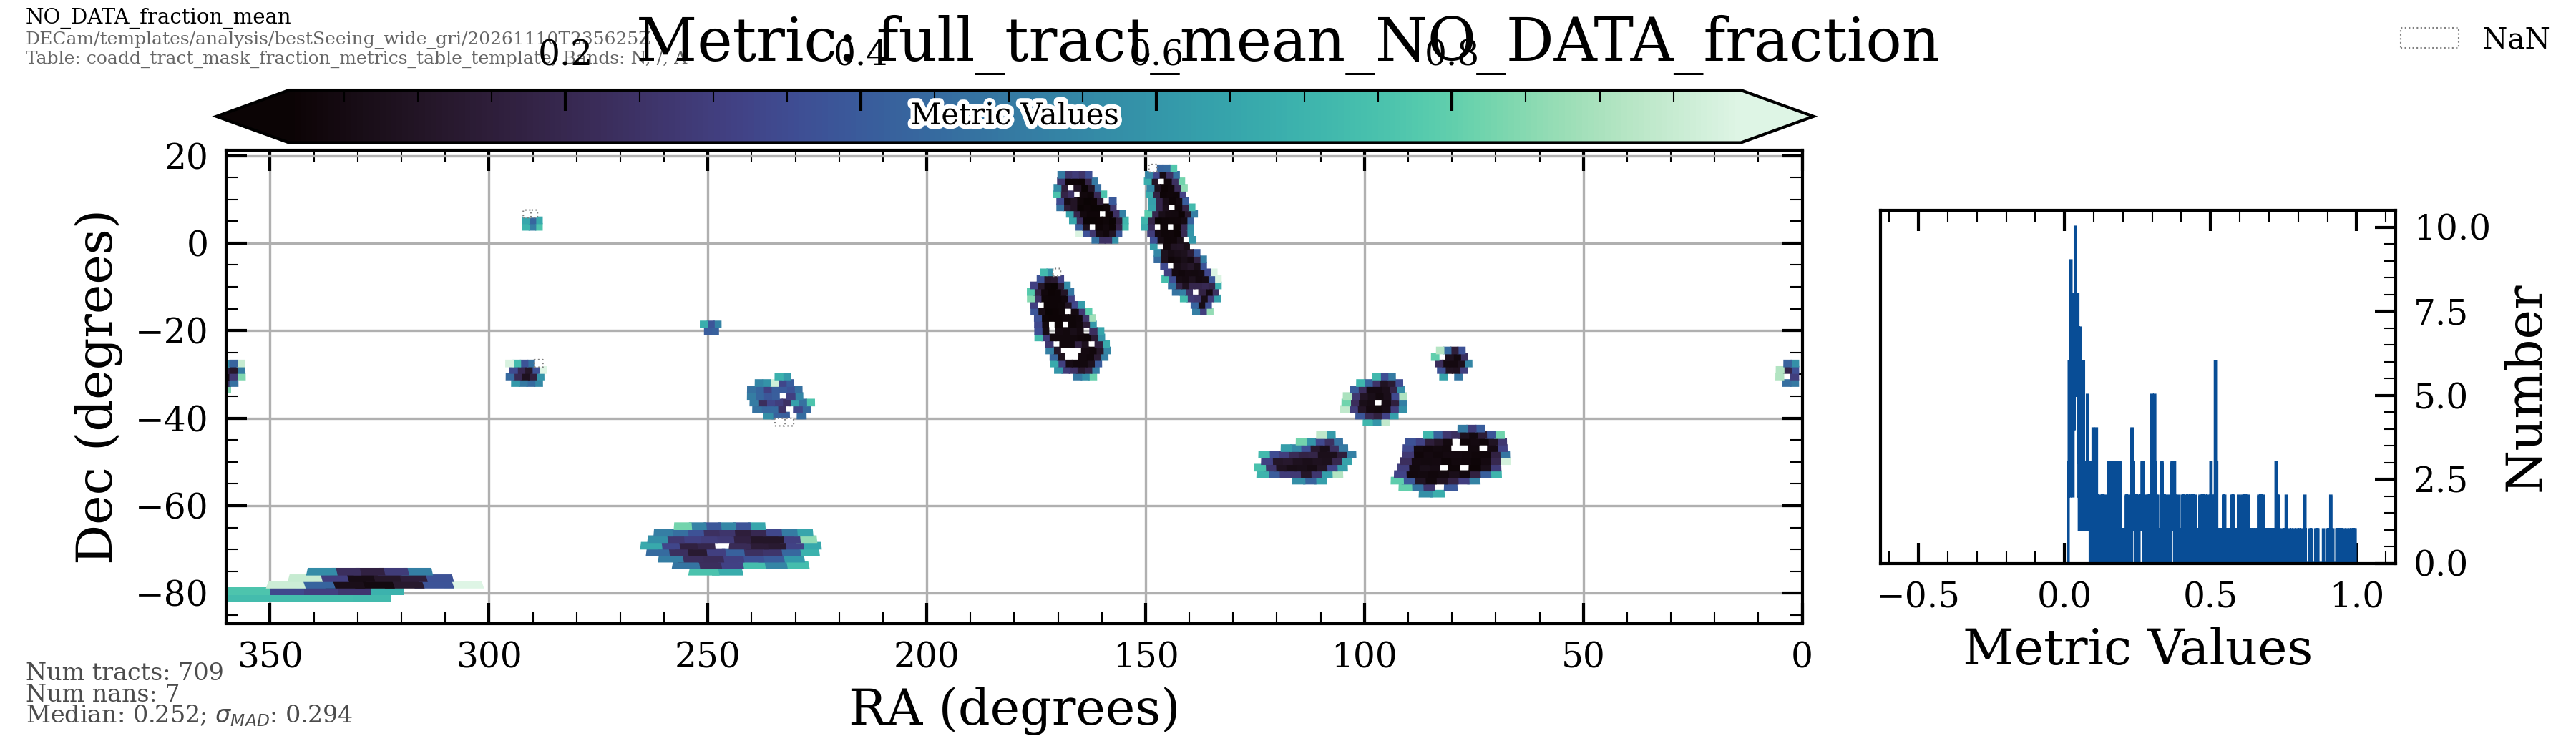

In [19]:
ws_types = sorted(t for t in butler.collections.query_info(ANALYSIS_RUN, include_summary=True)[0].dataset_types
                  if t.endswith("_WholeSkyPlot"))
if not ws_types:
    display(Markdown("No whole-sky plots in this RUN yet."))
# for t in ws_types:
for t in ["coadd_mask_fraction_template_NO_DATA_fraction_mean_WholeSkyPlot"]:
    for r in sorted(refs(t, ANALYSIS_RUN), key=lambda r: str(r.dataId.get("band", ""))):
        display(Markdown(f"`{t}` {dict(r.dataId.mapping)}"))
        show_png(r, width=900)

### Per-tract n_image depth plots

The tracts in `SHOW_DEPTH_PLOT_TRACTS`, or the shallowest tracts from Section 2.

1051 depth plots in the RUN


**tract 4052**

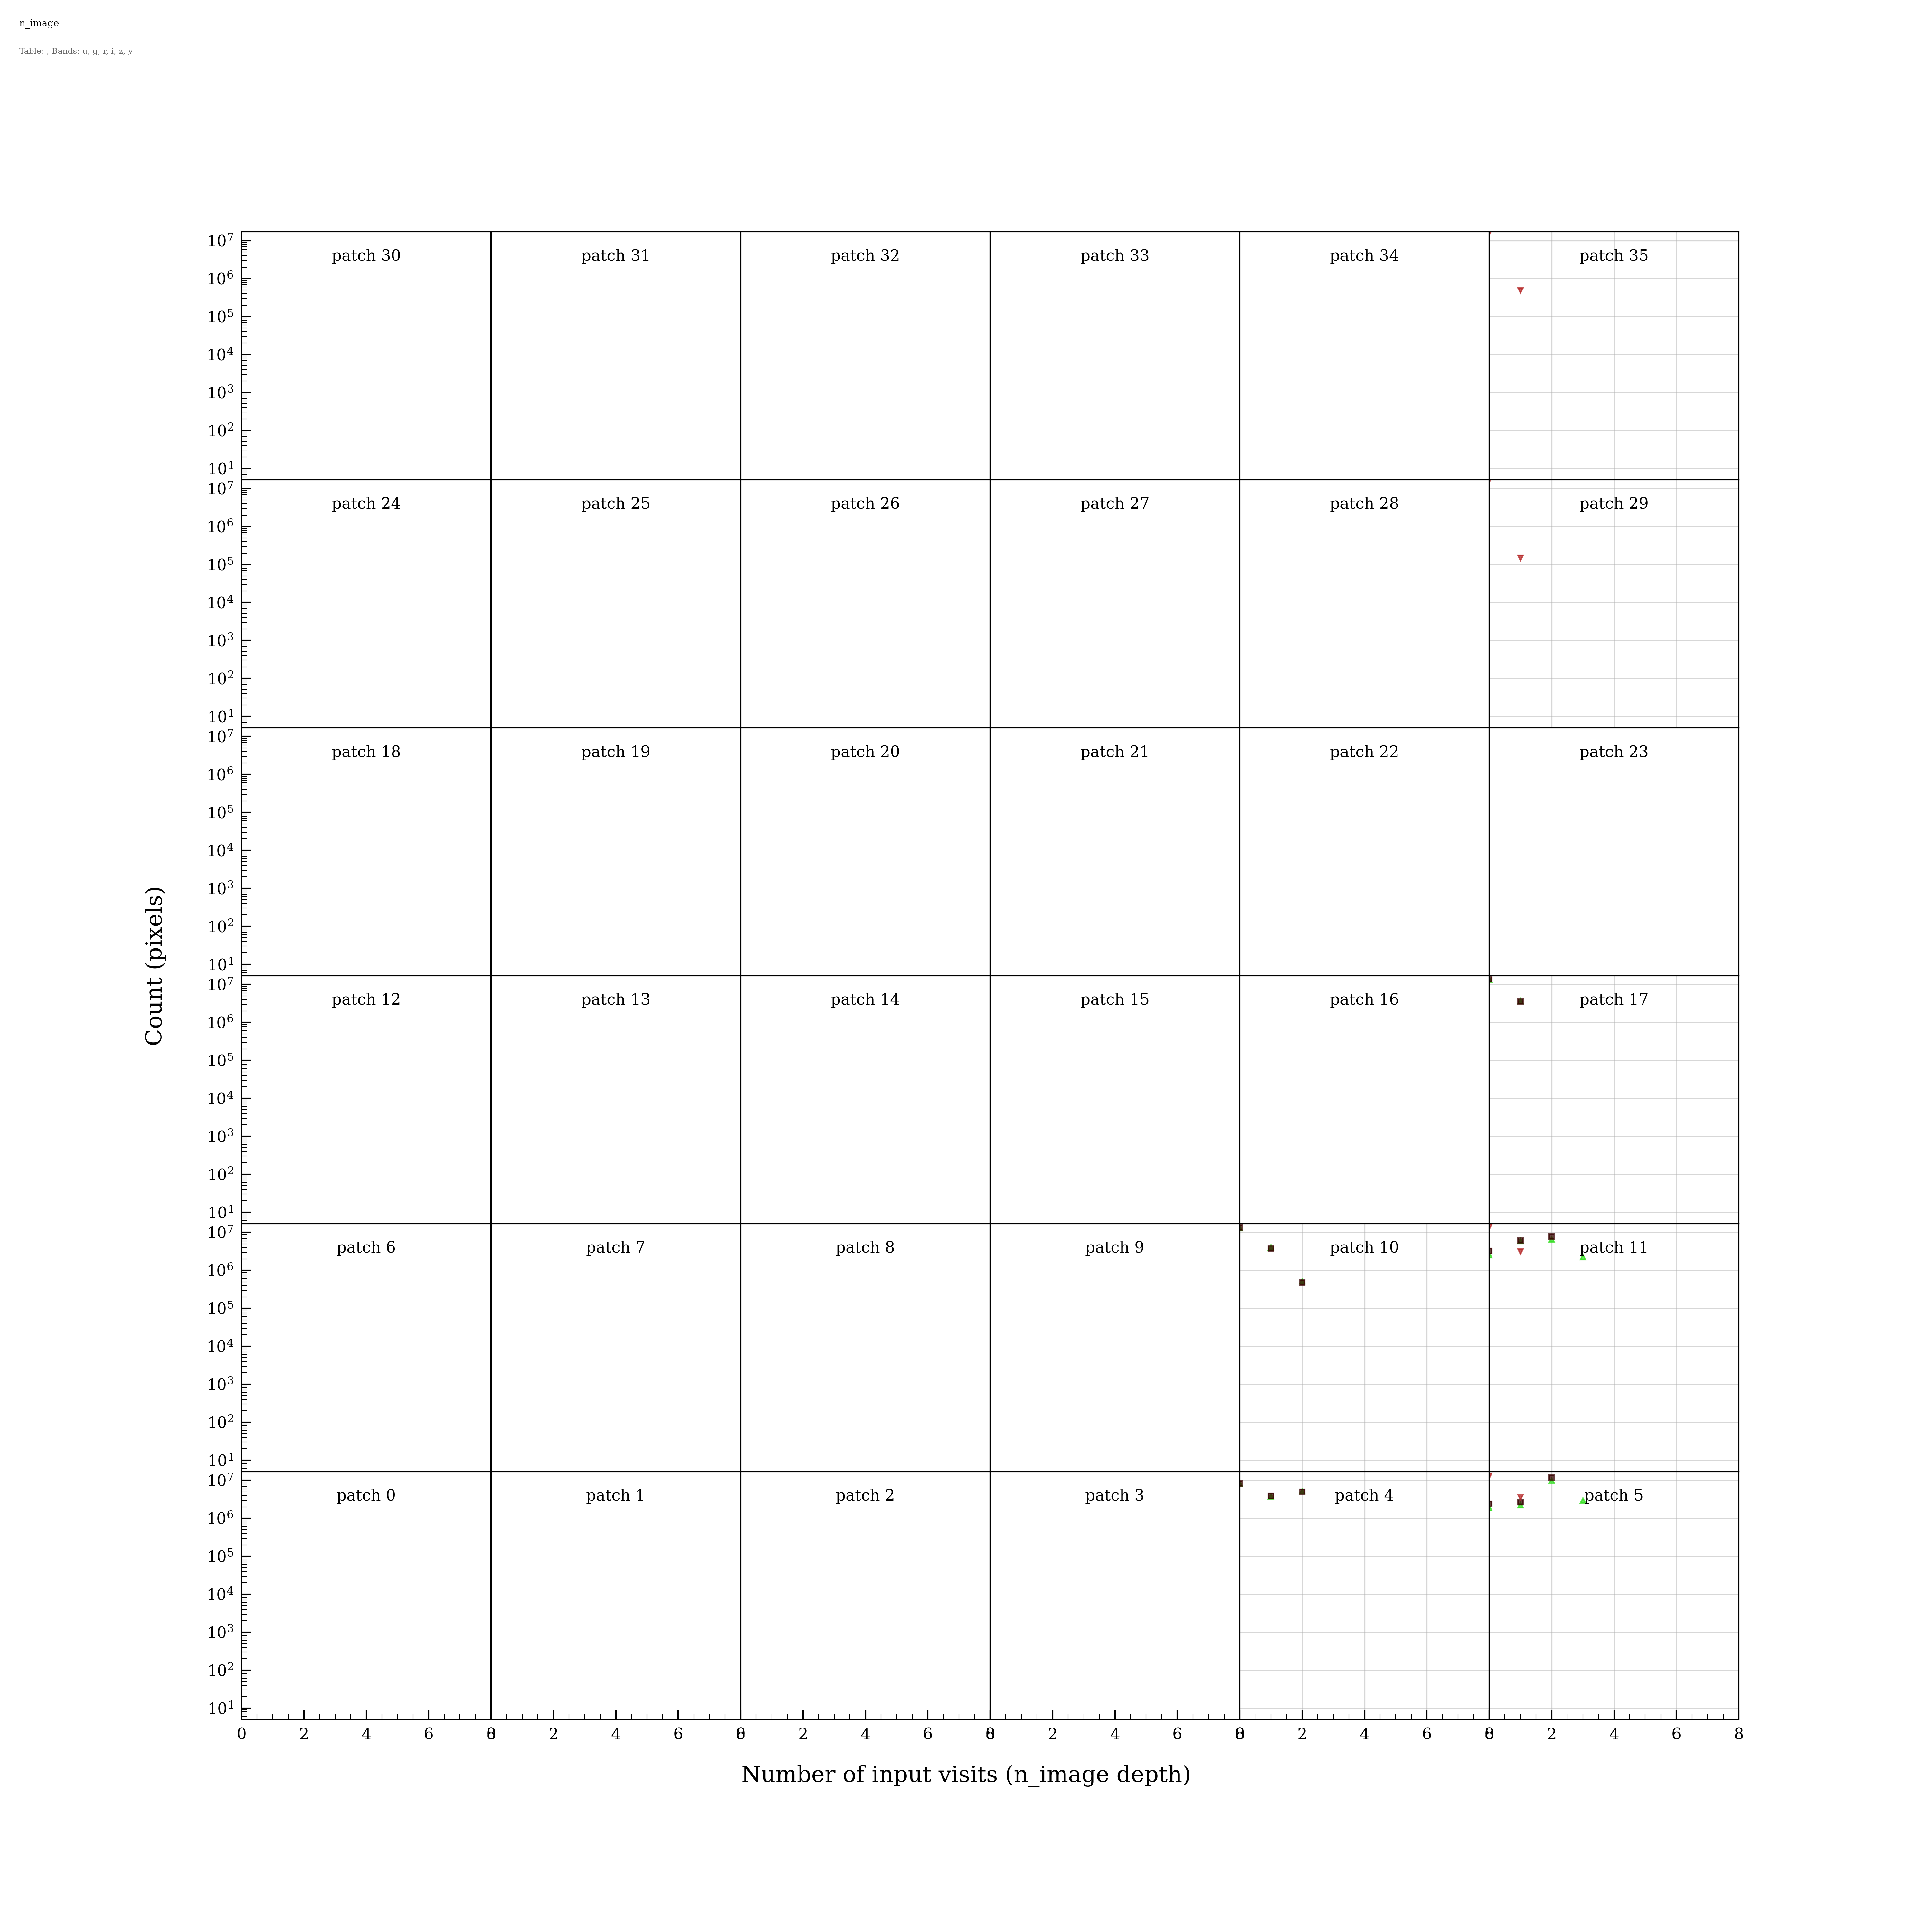

**tract 7635**

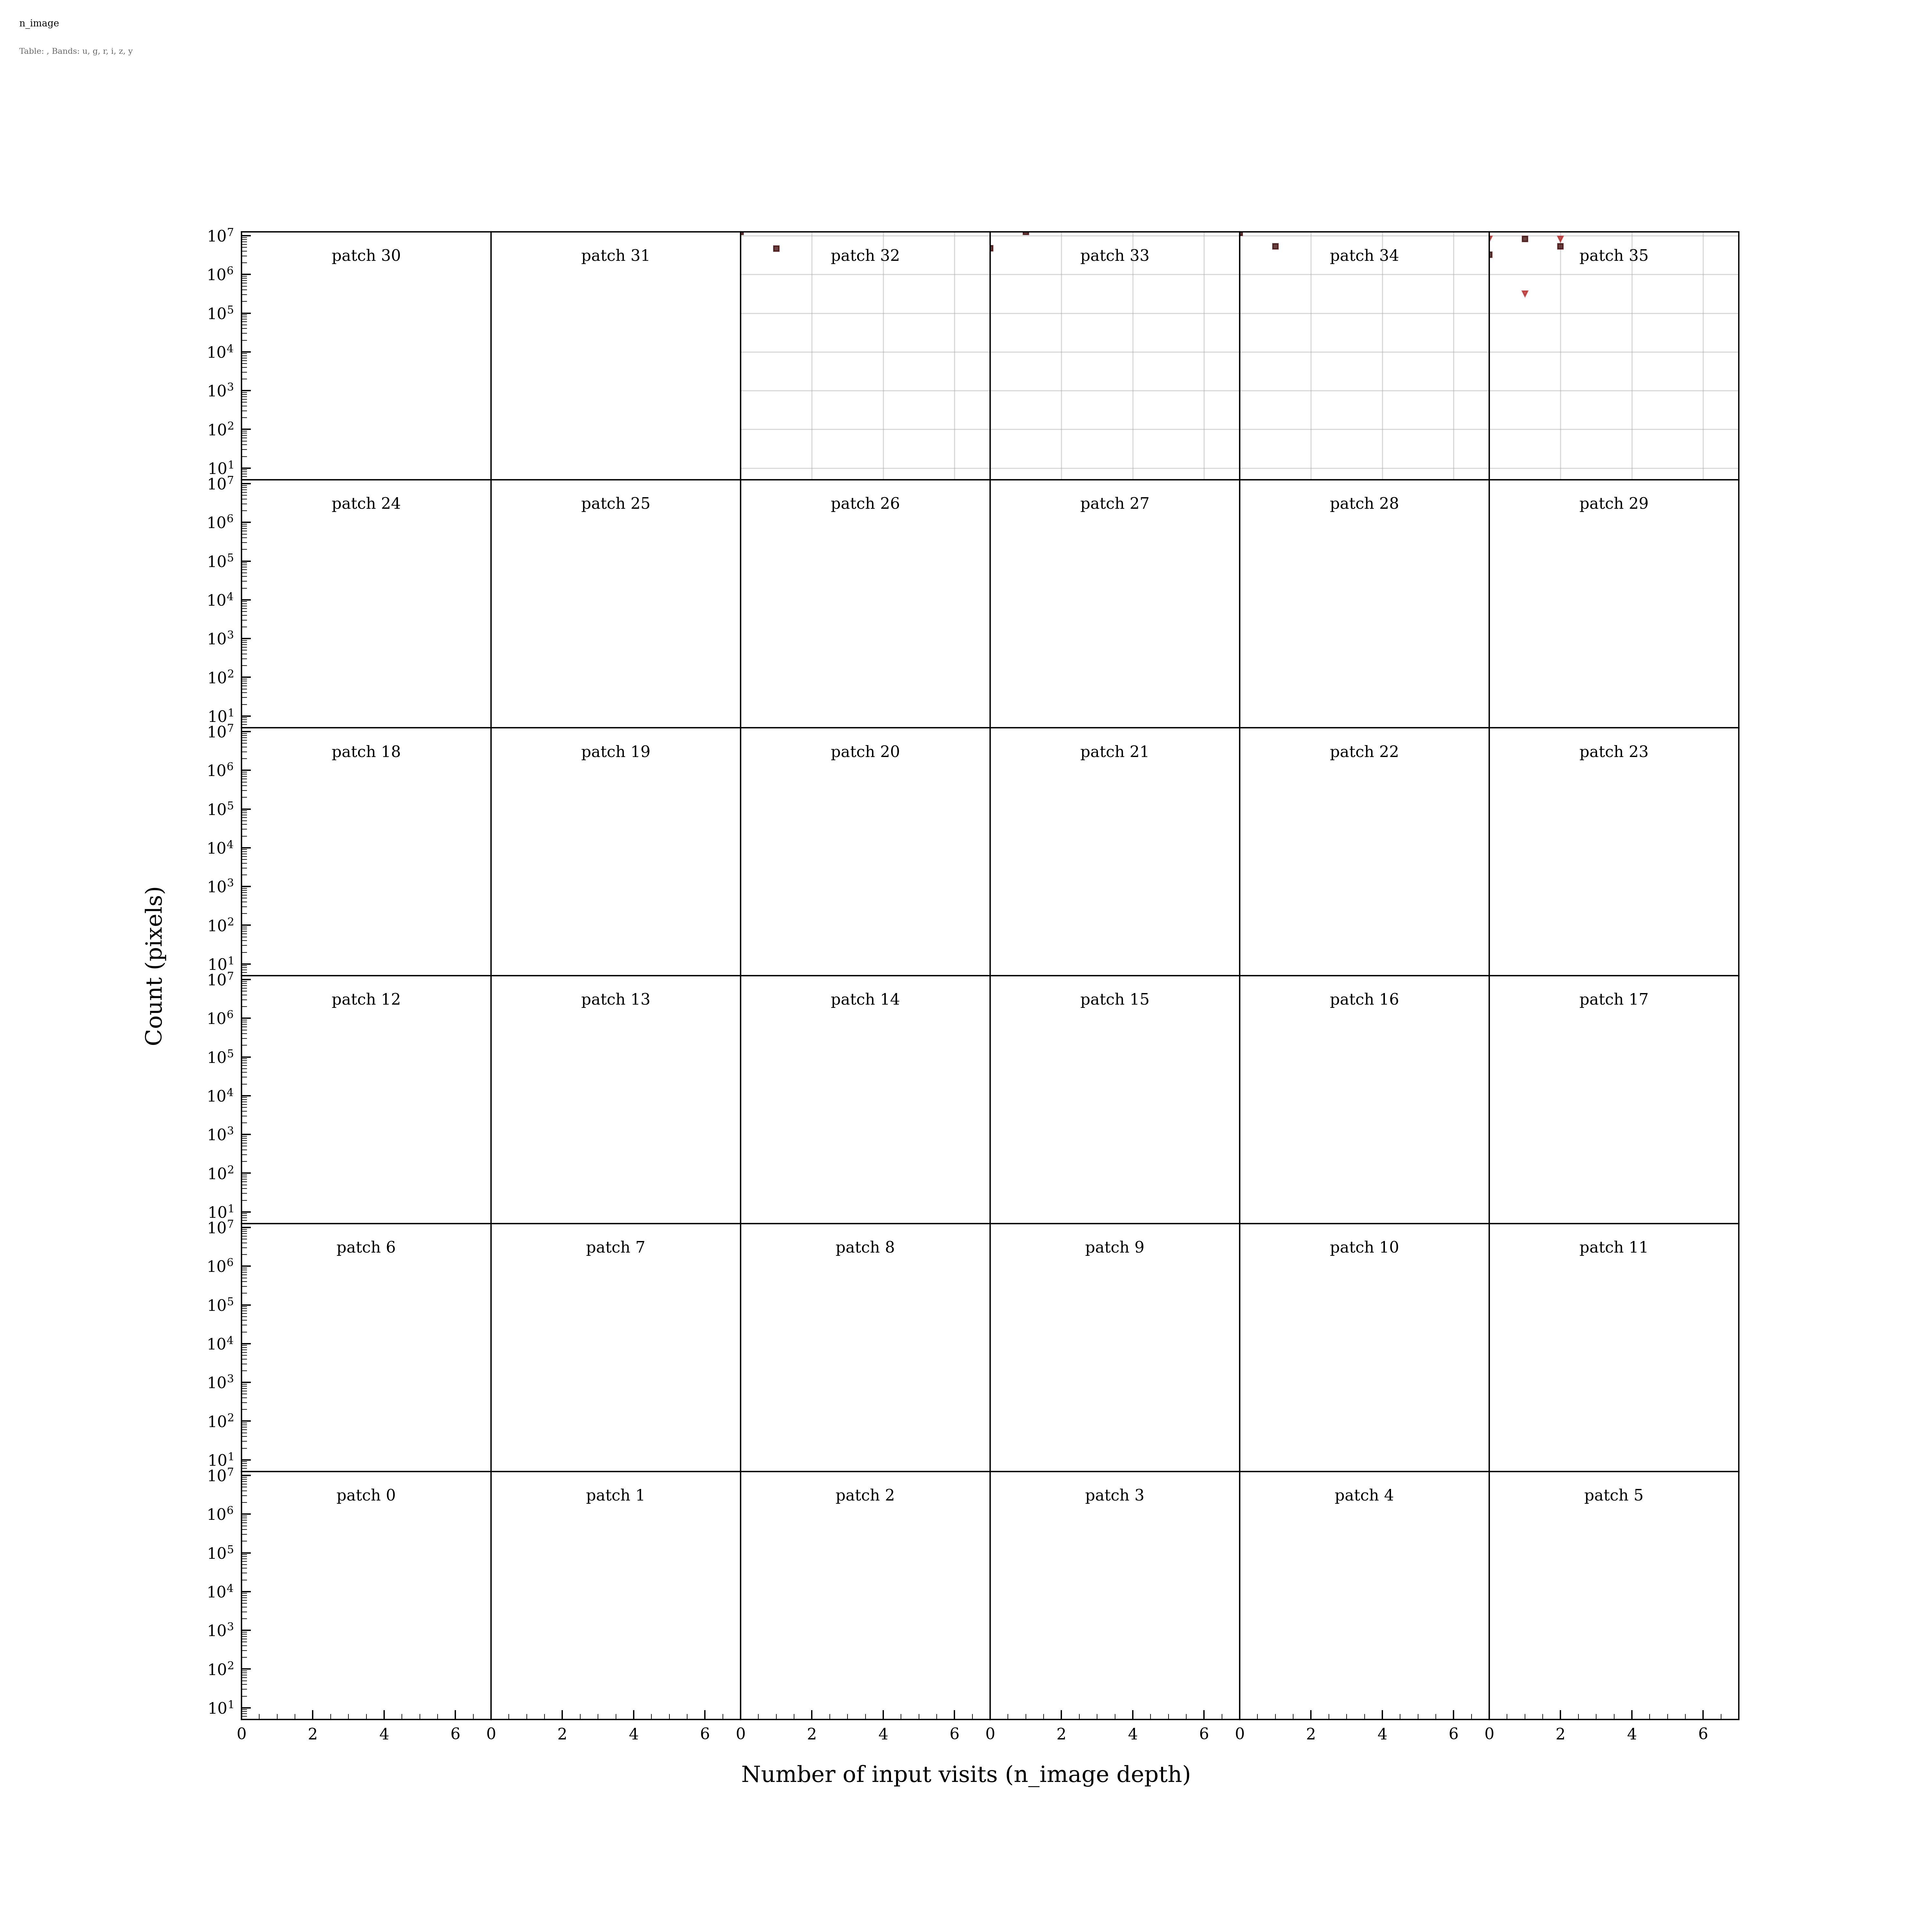

**tract 4455**

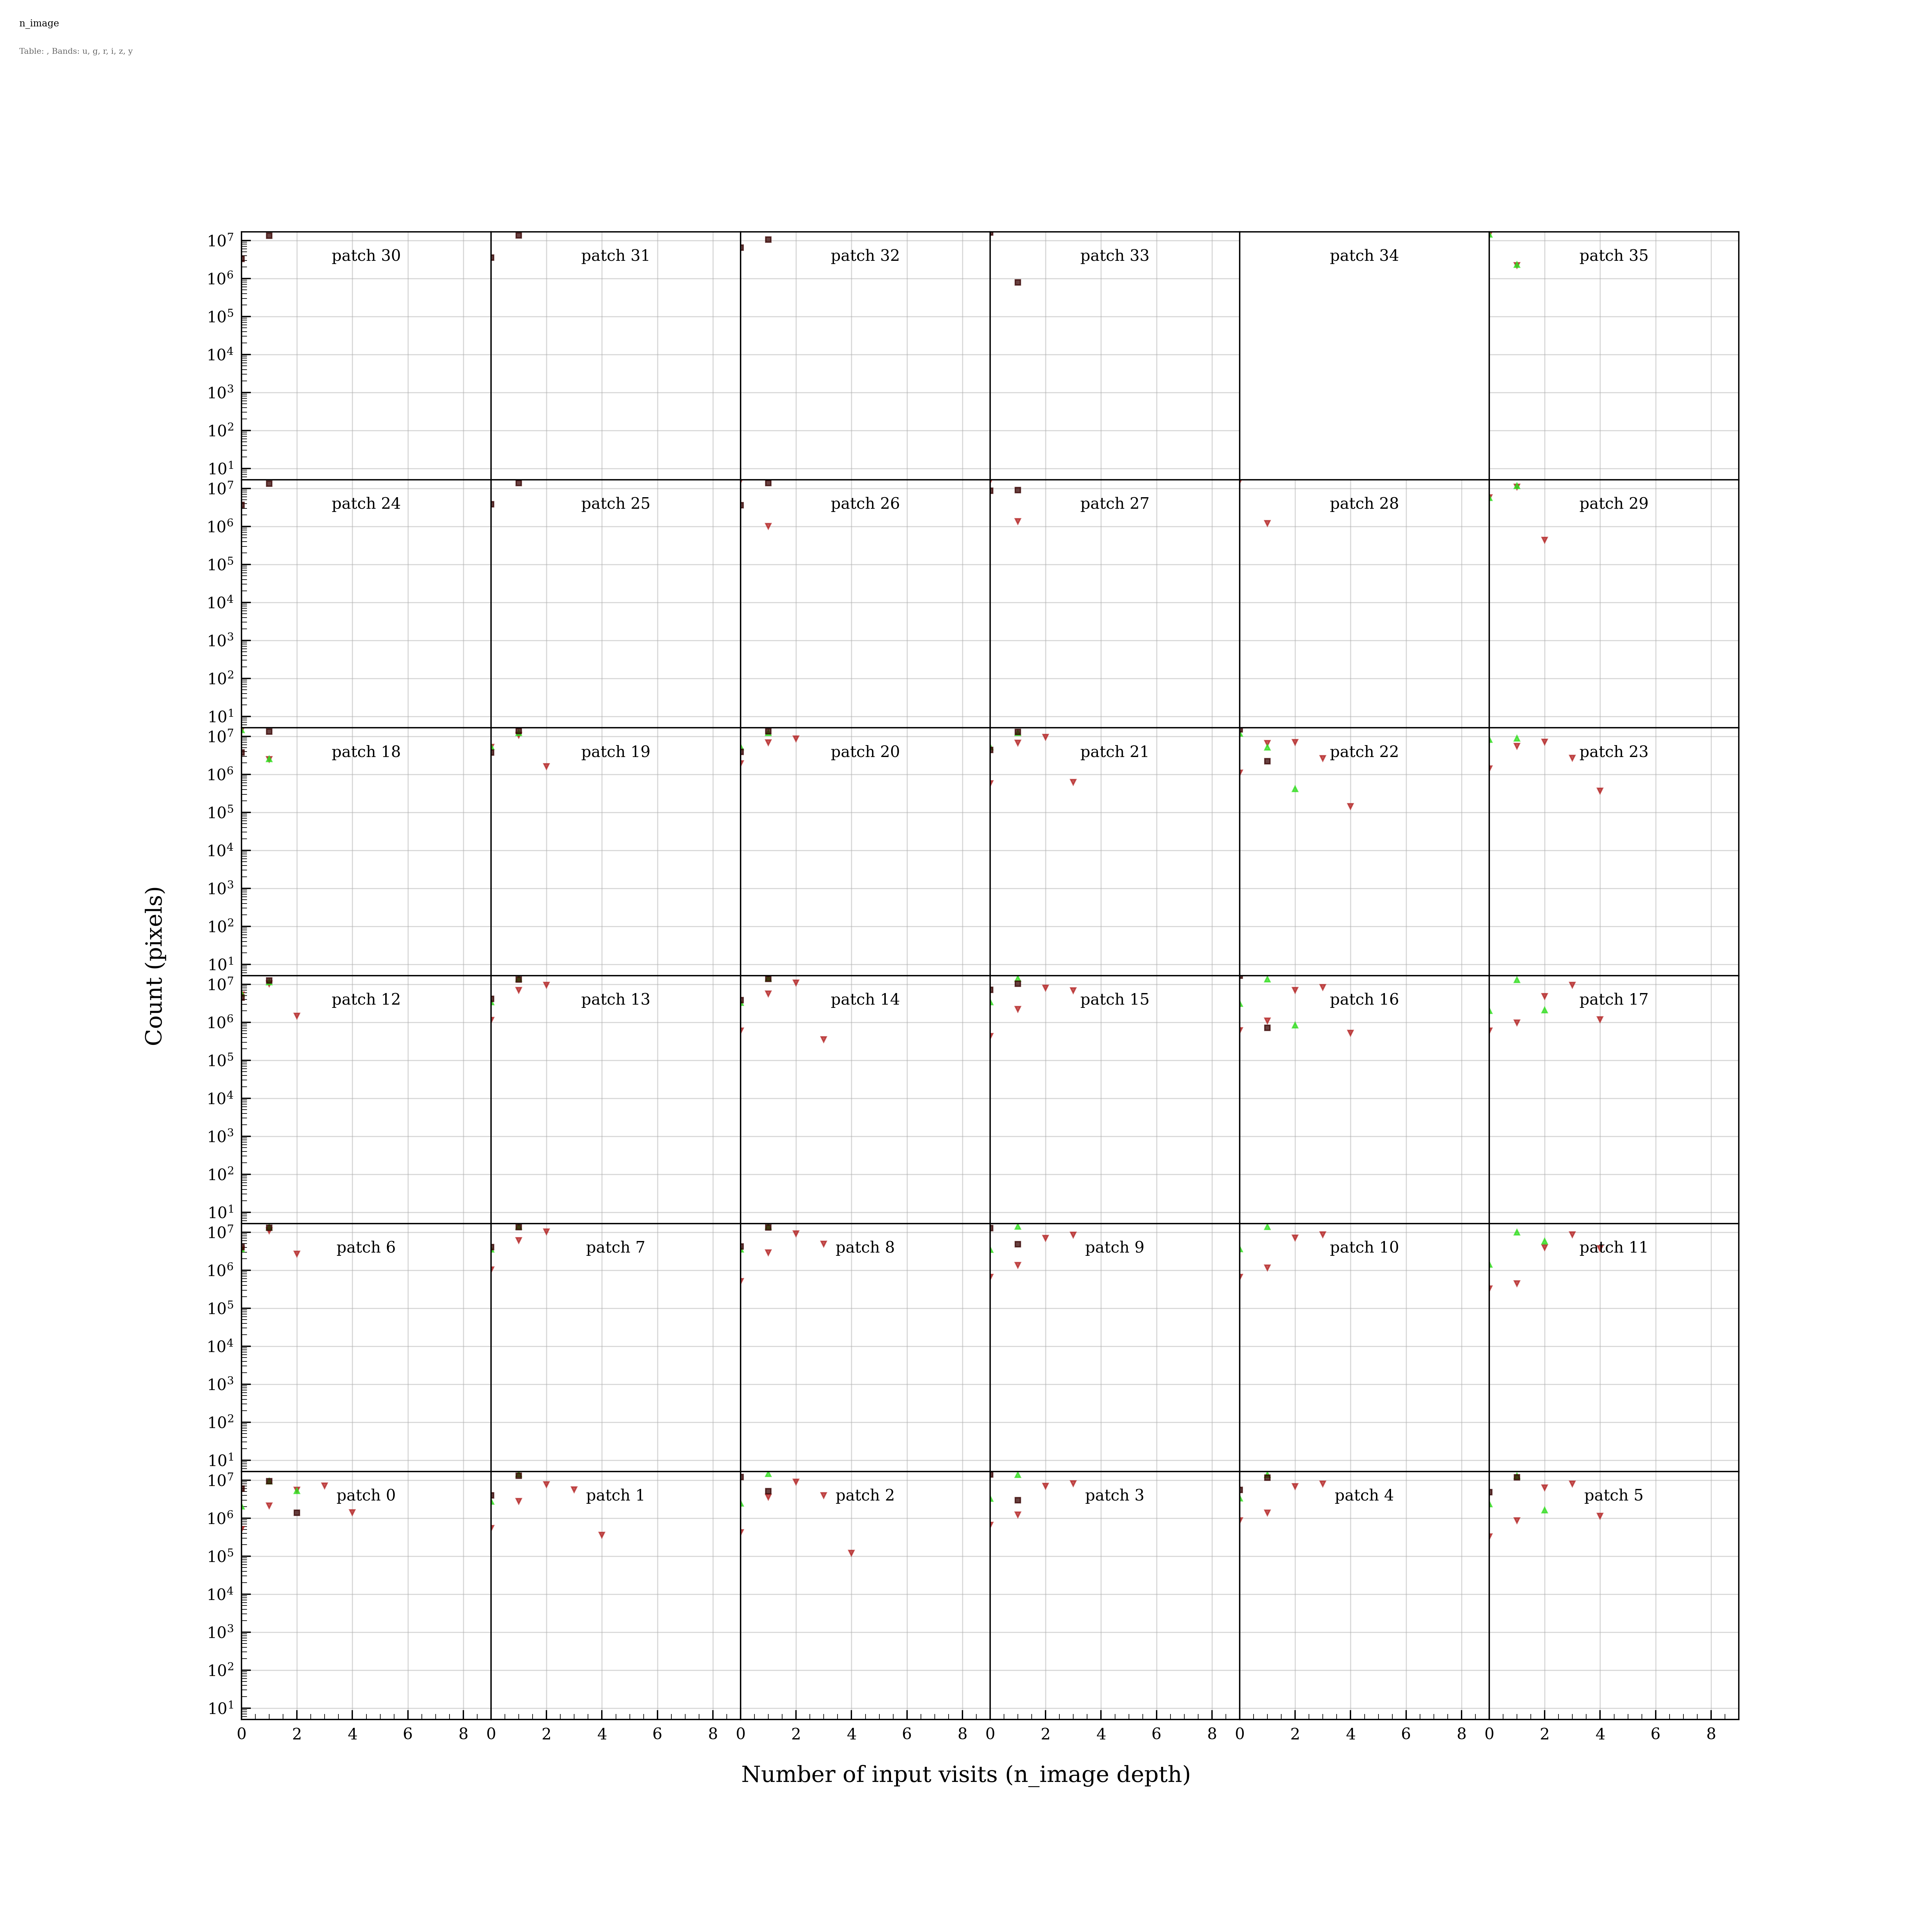

**tract 4454**

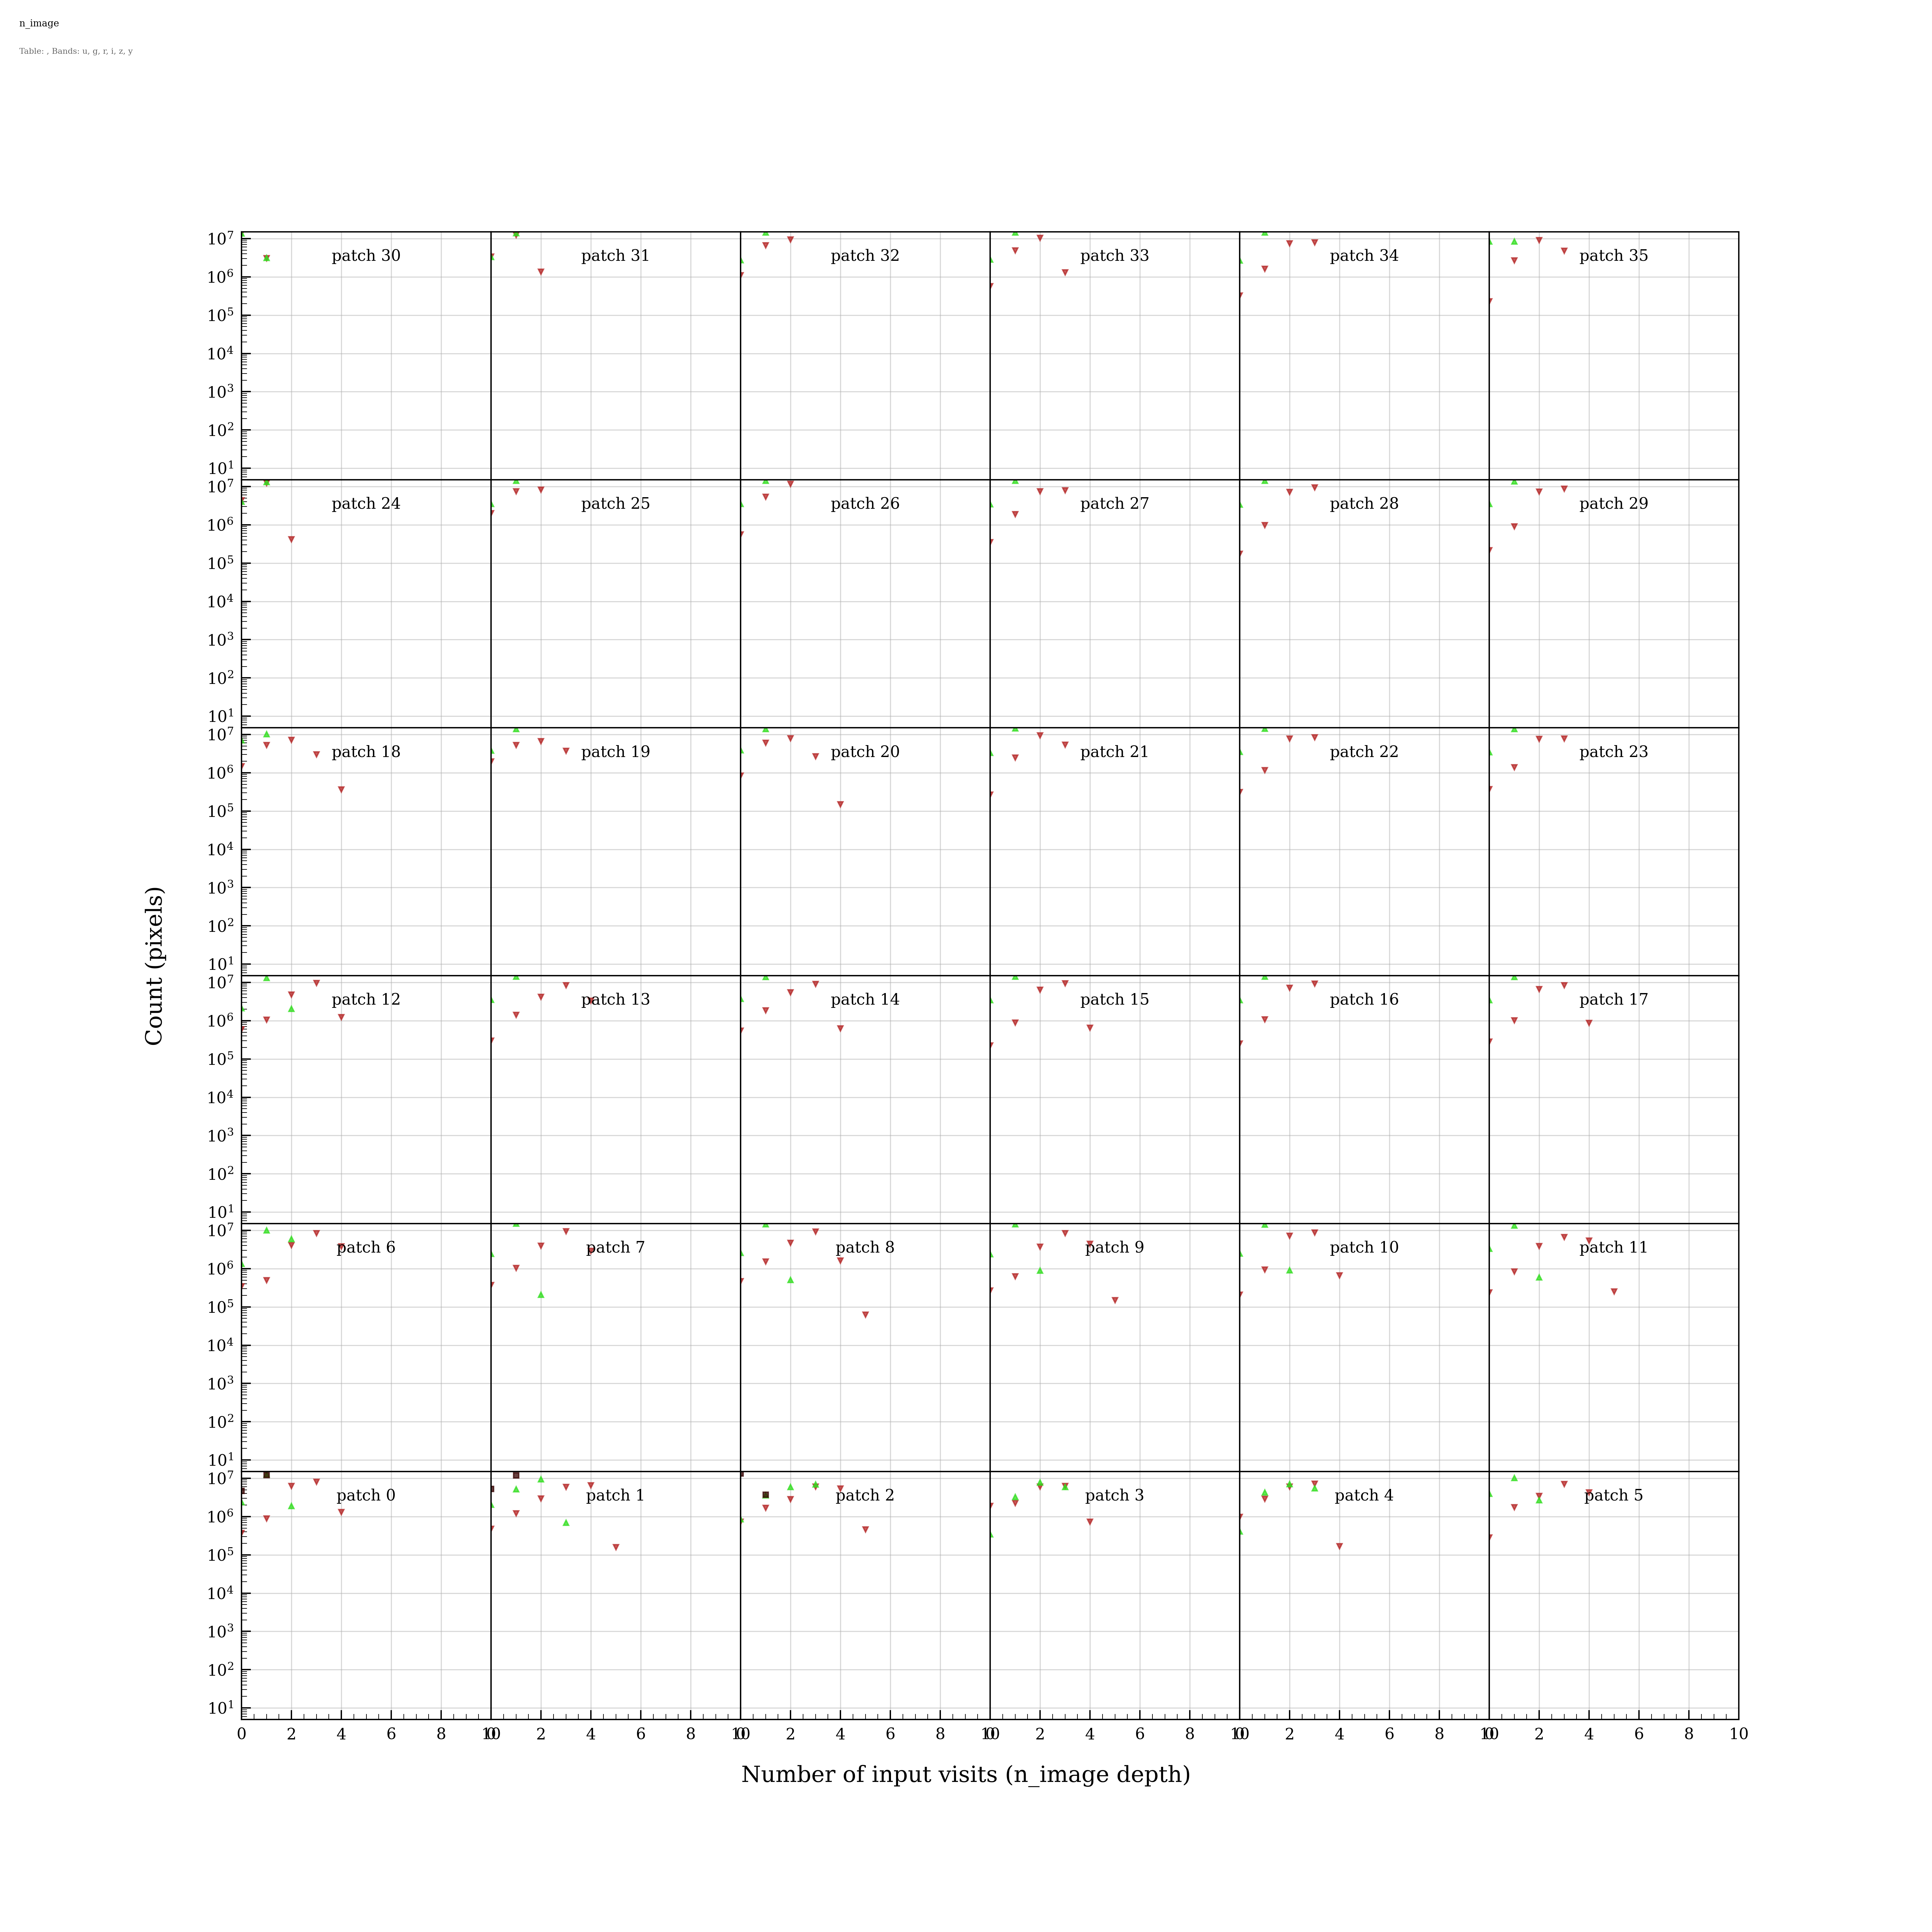

**tract 4391**

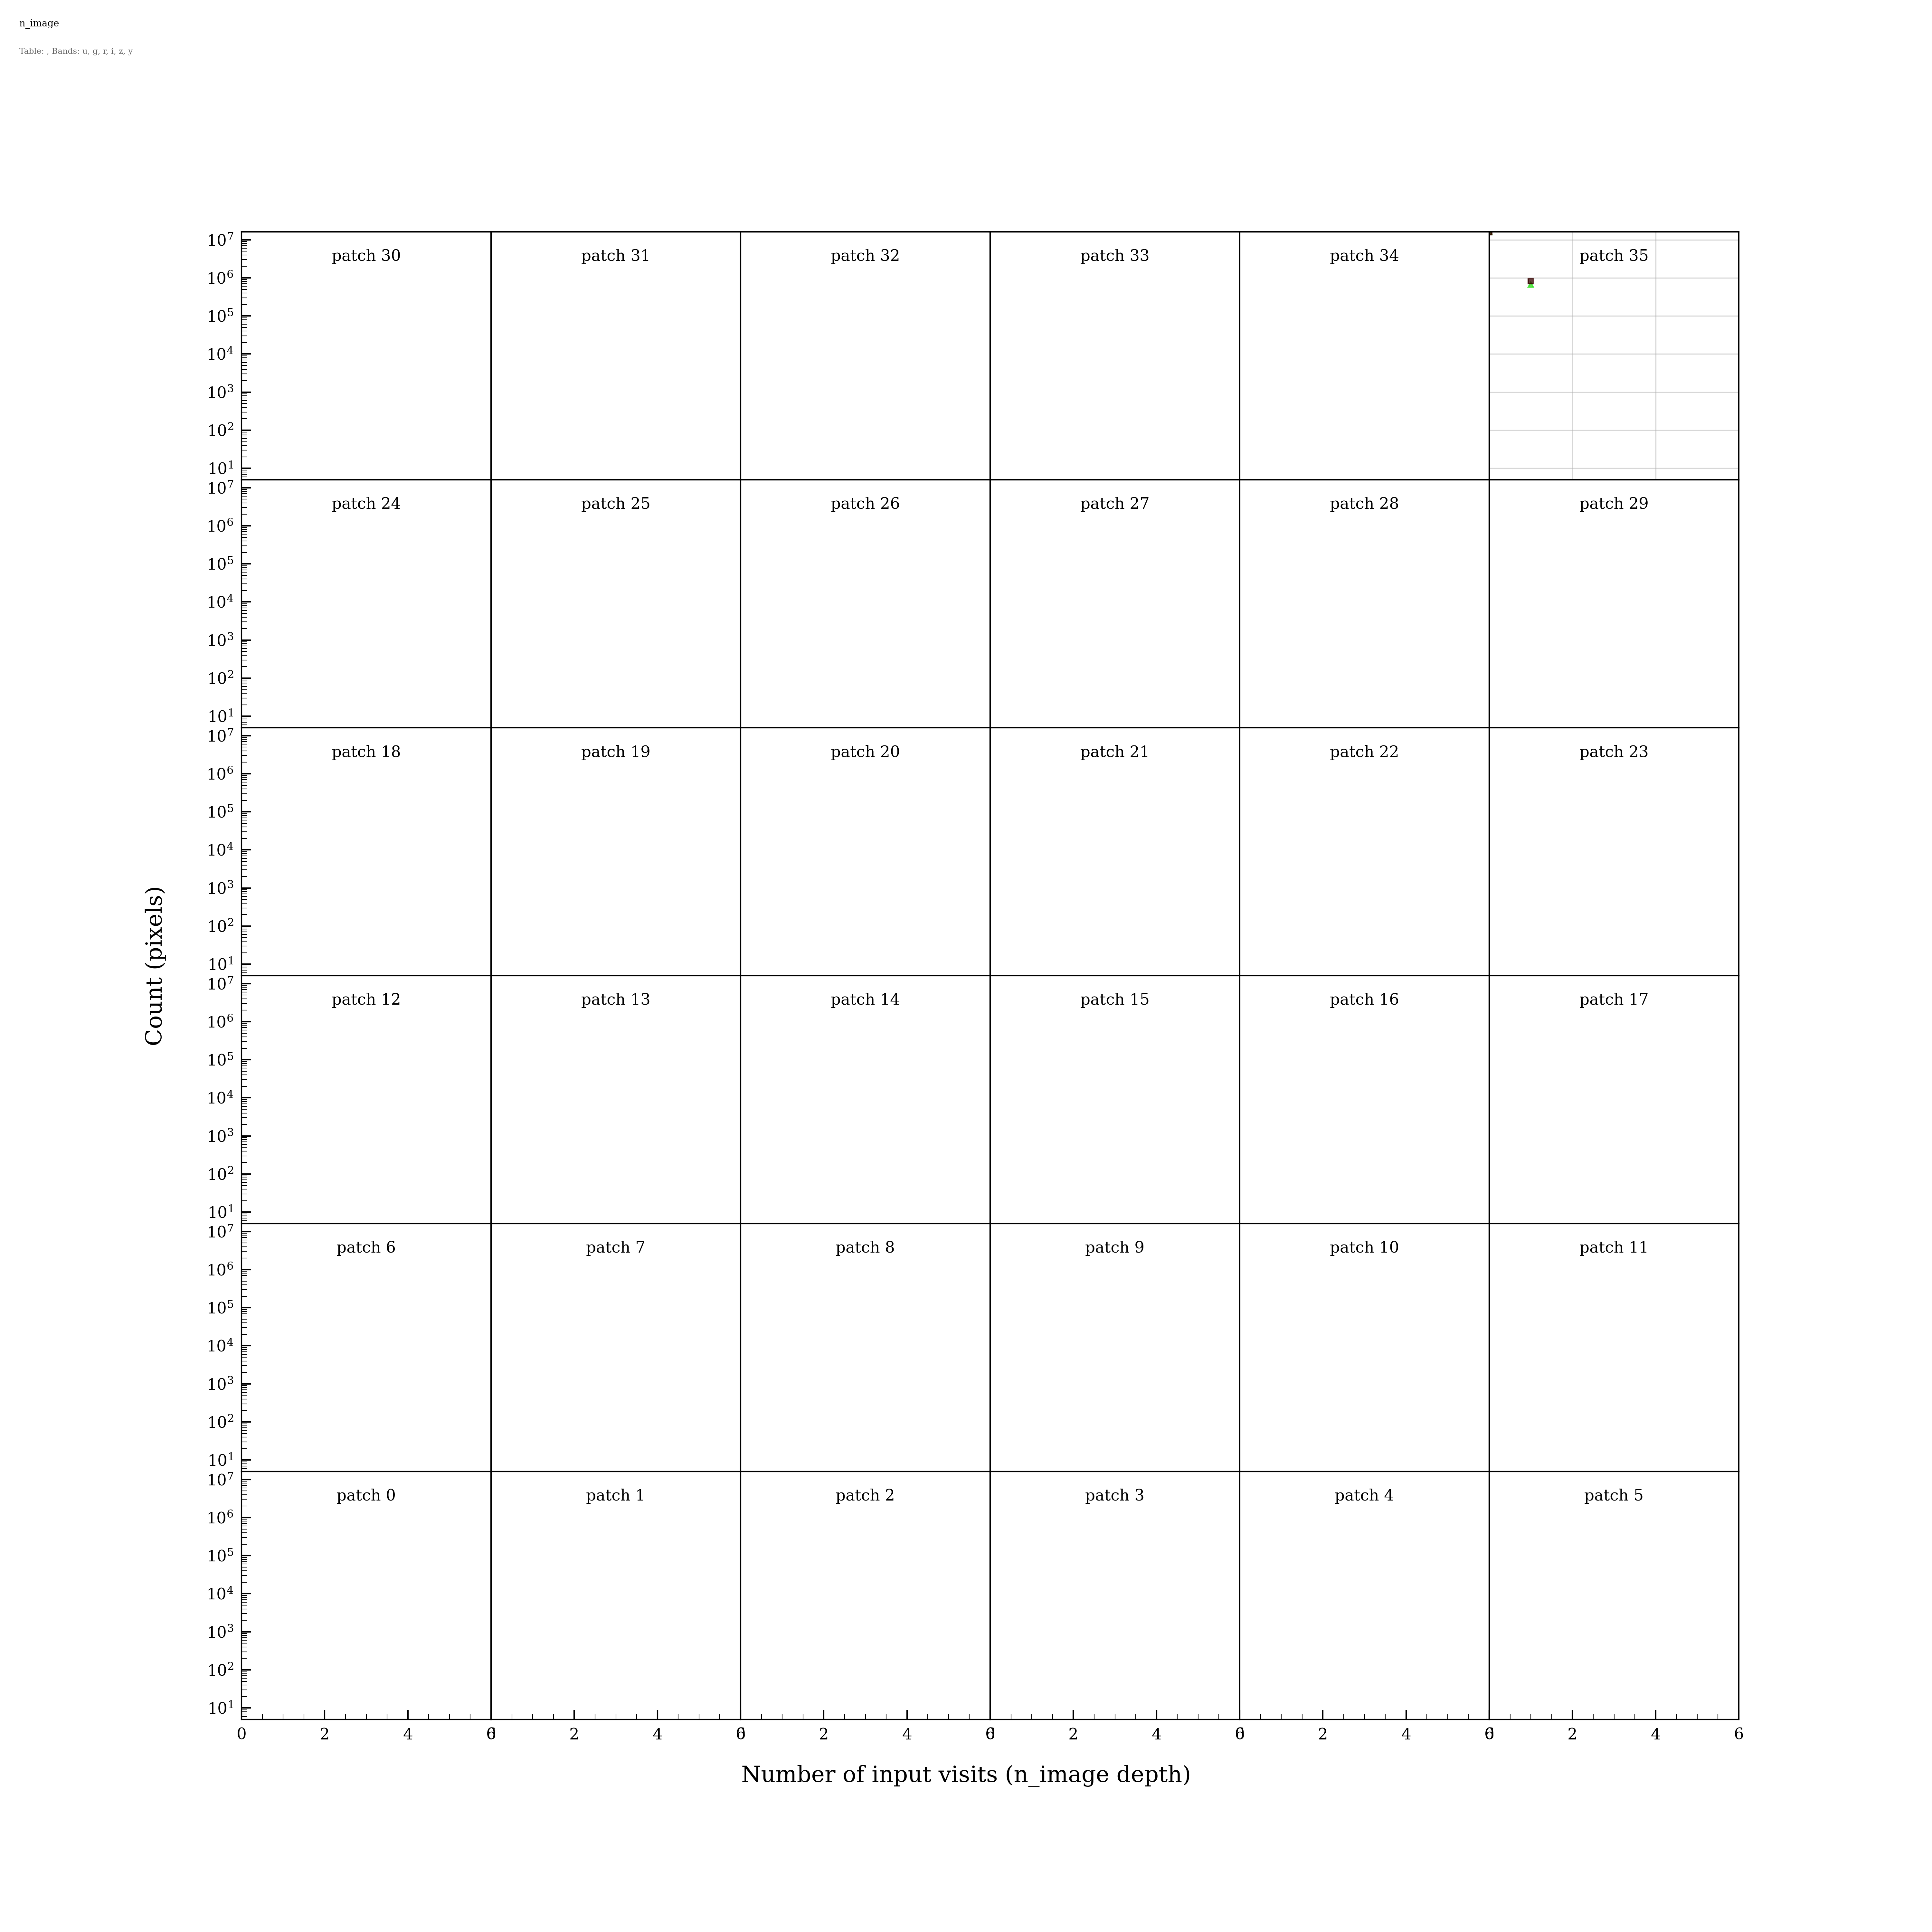

**tract 4324**

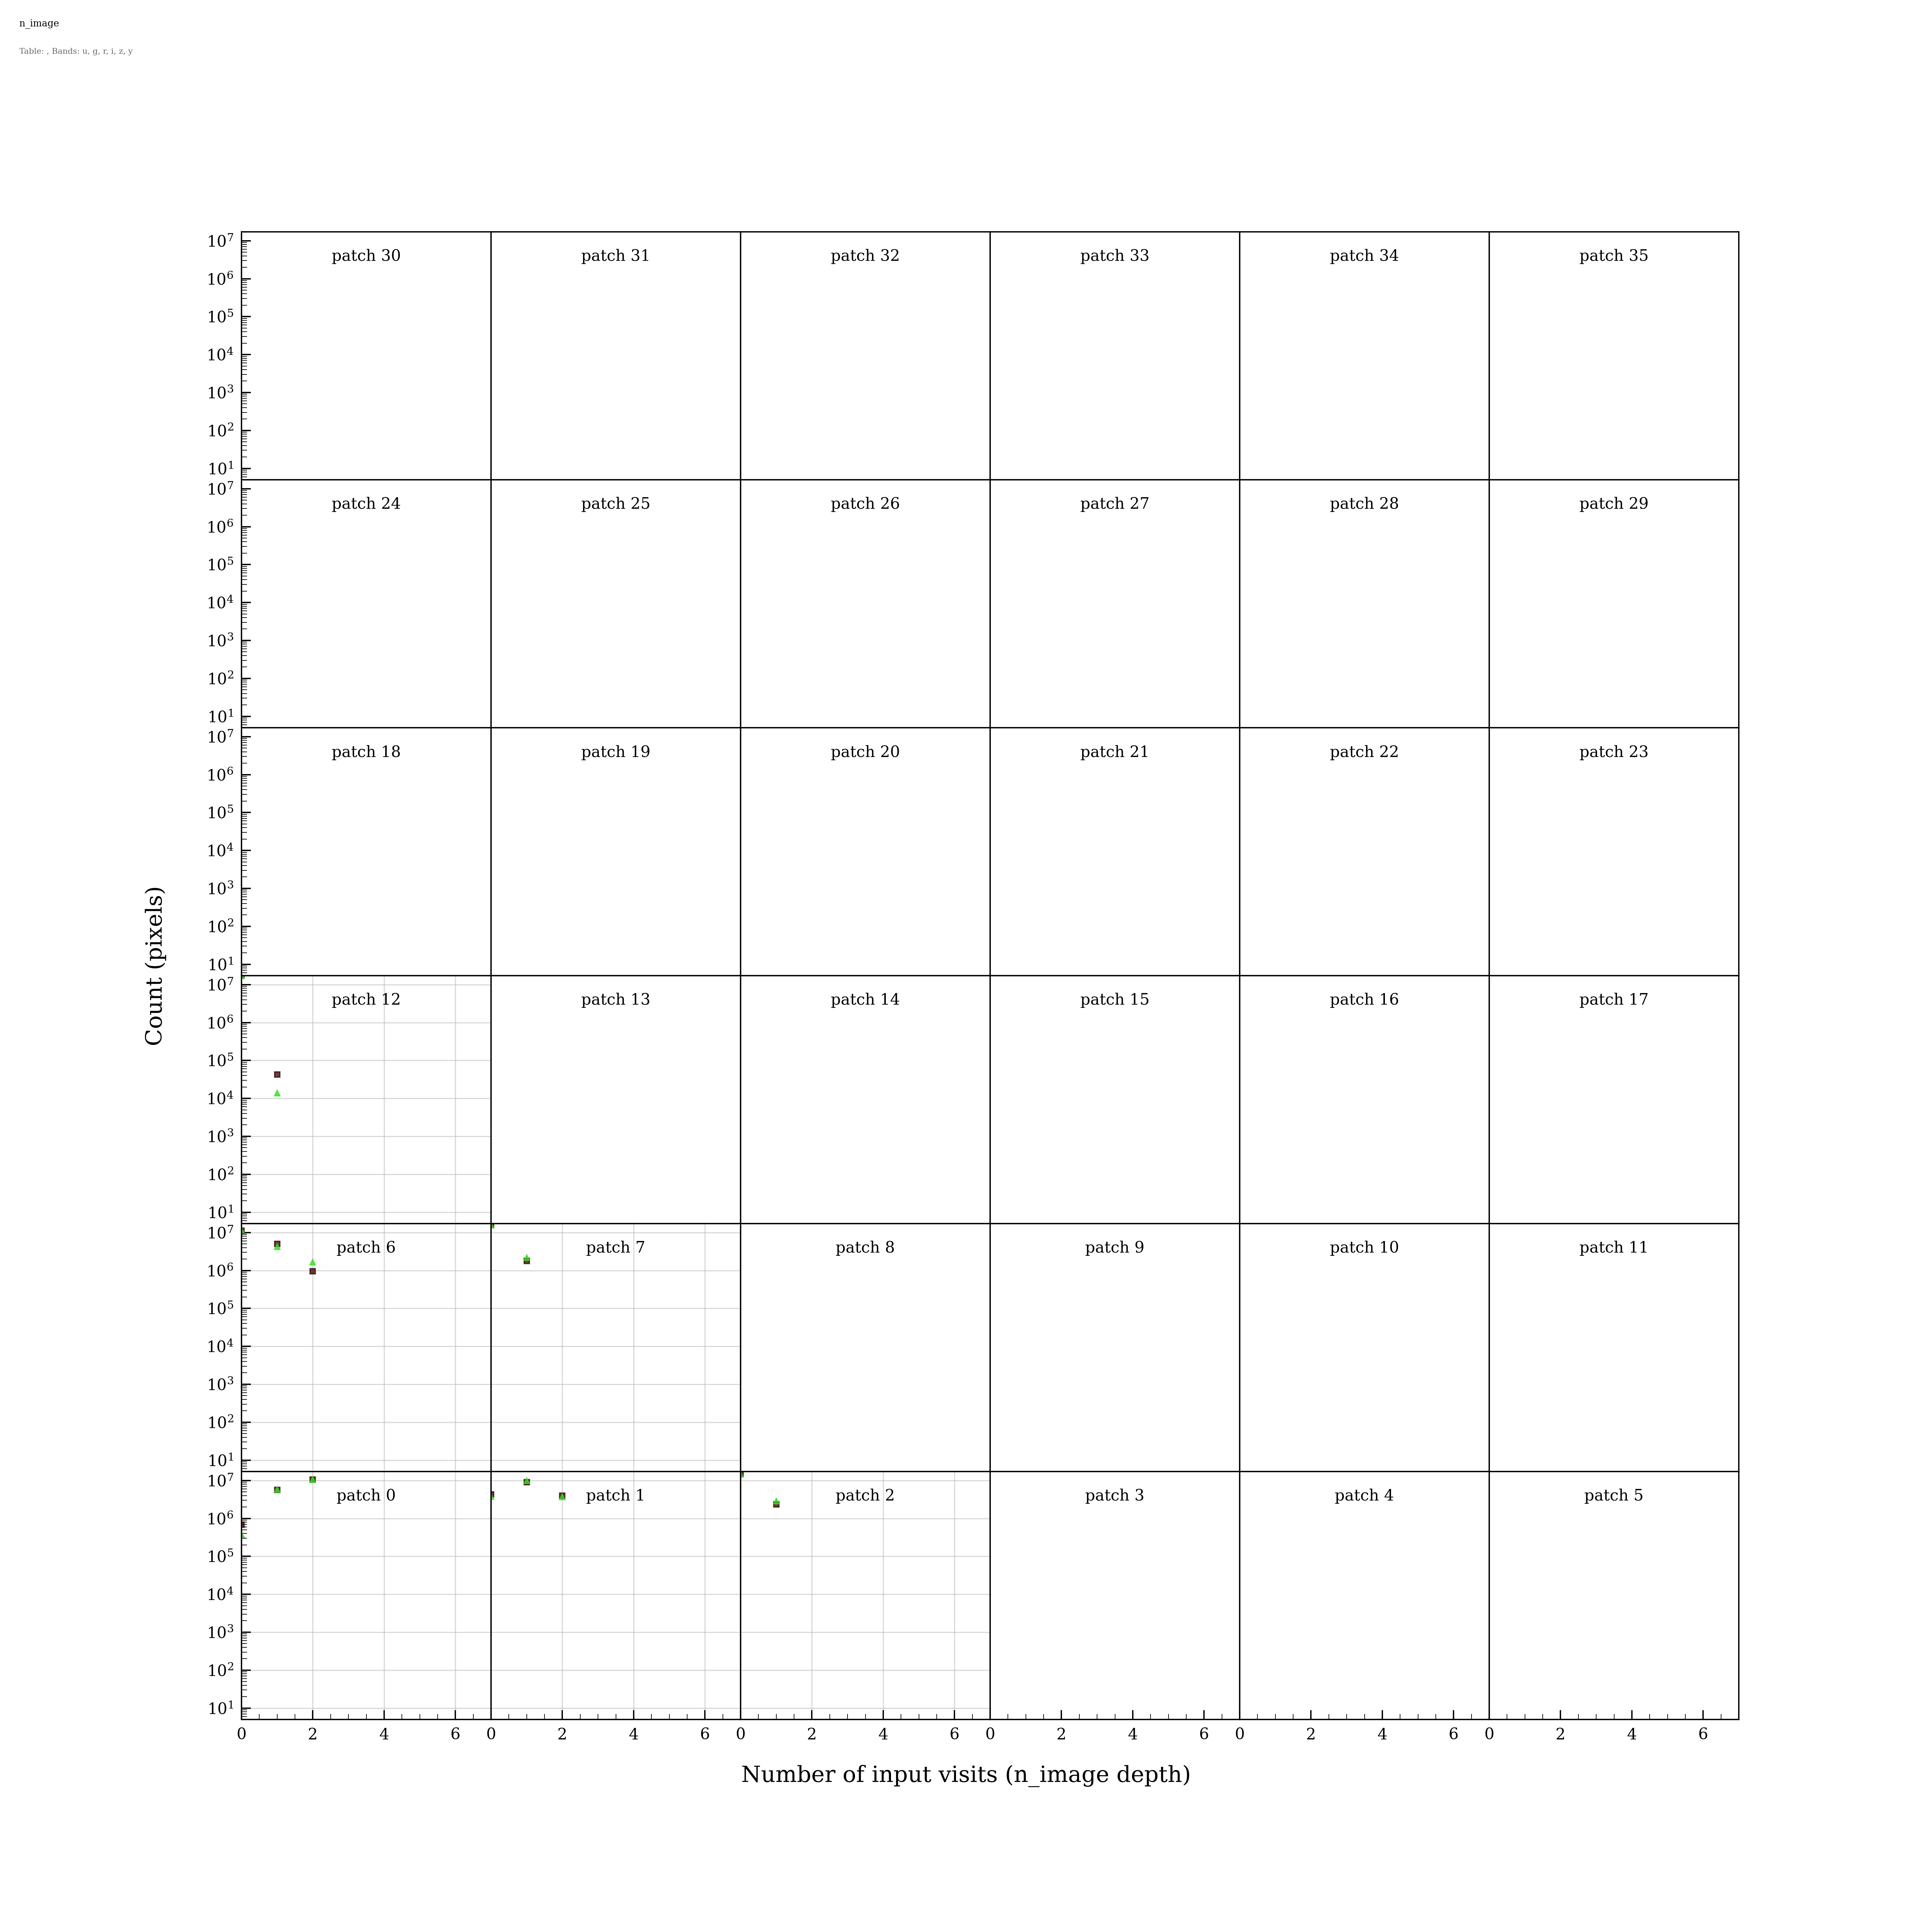

**tract 4253**

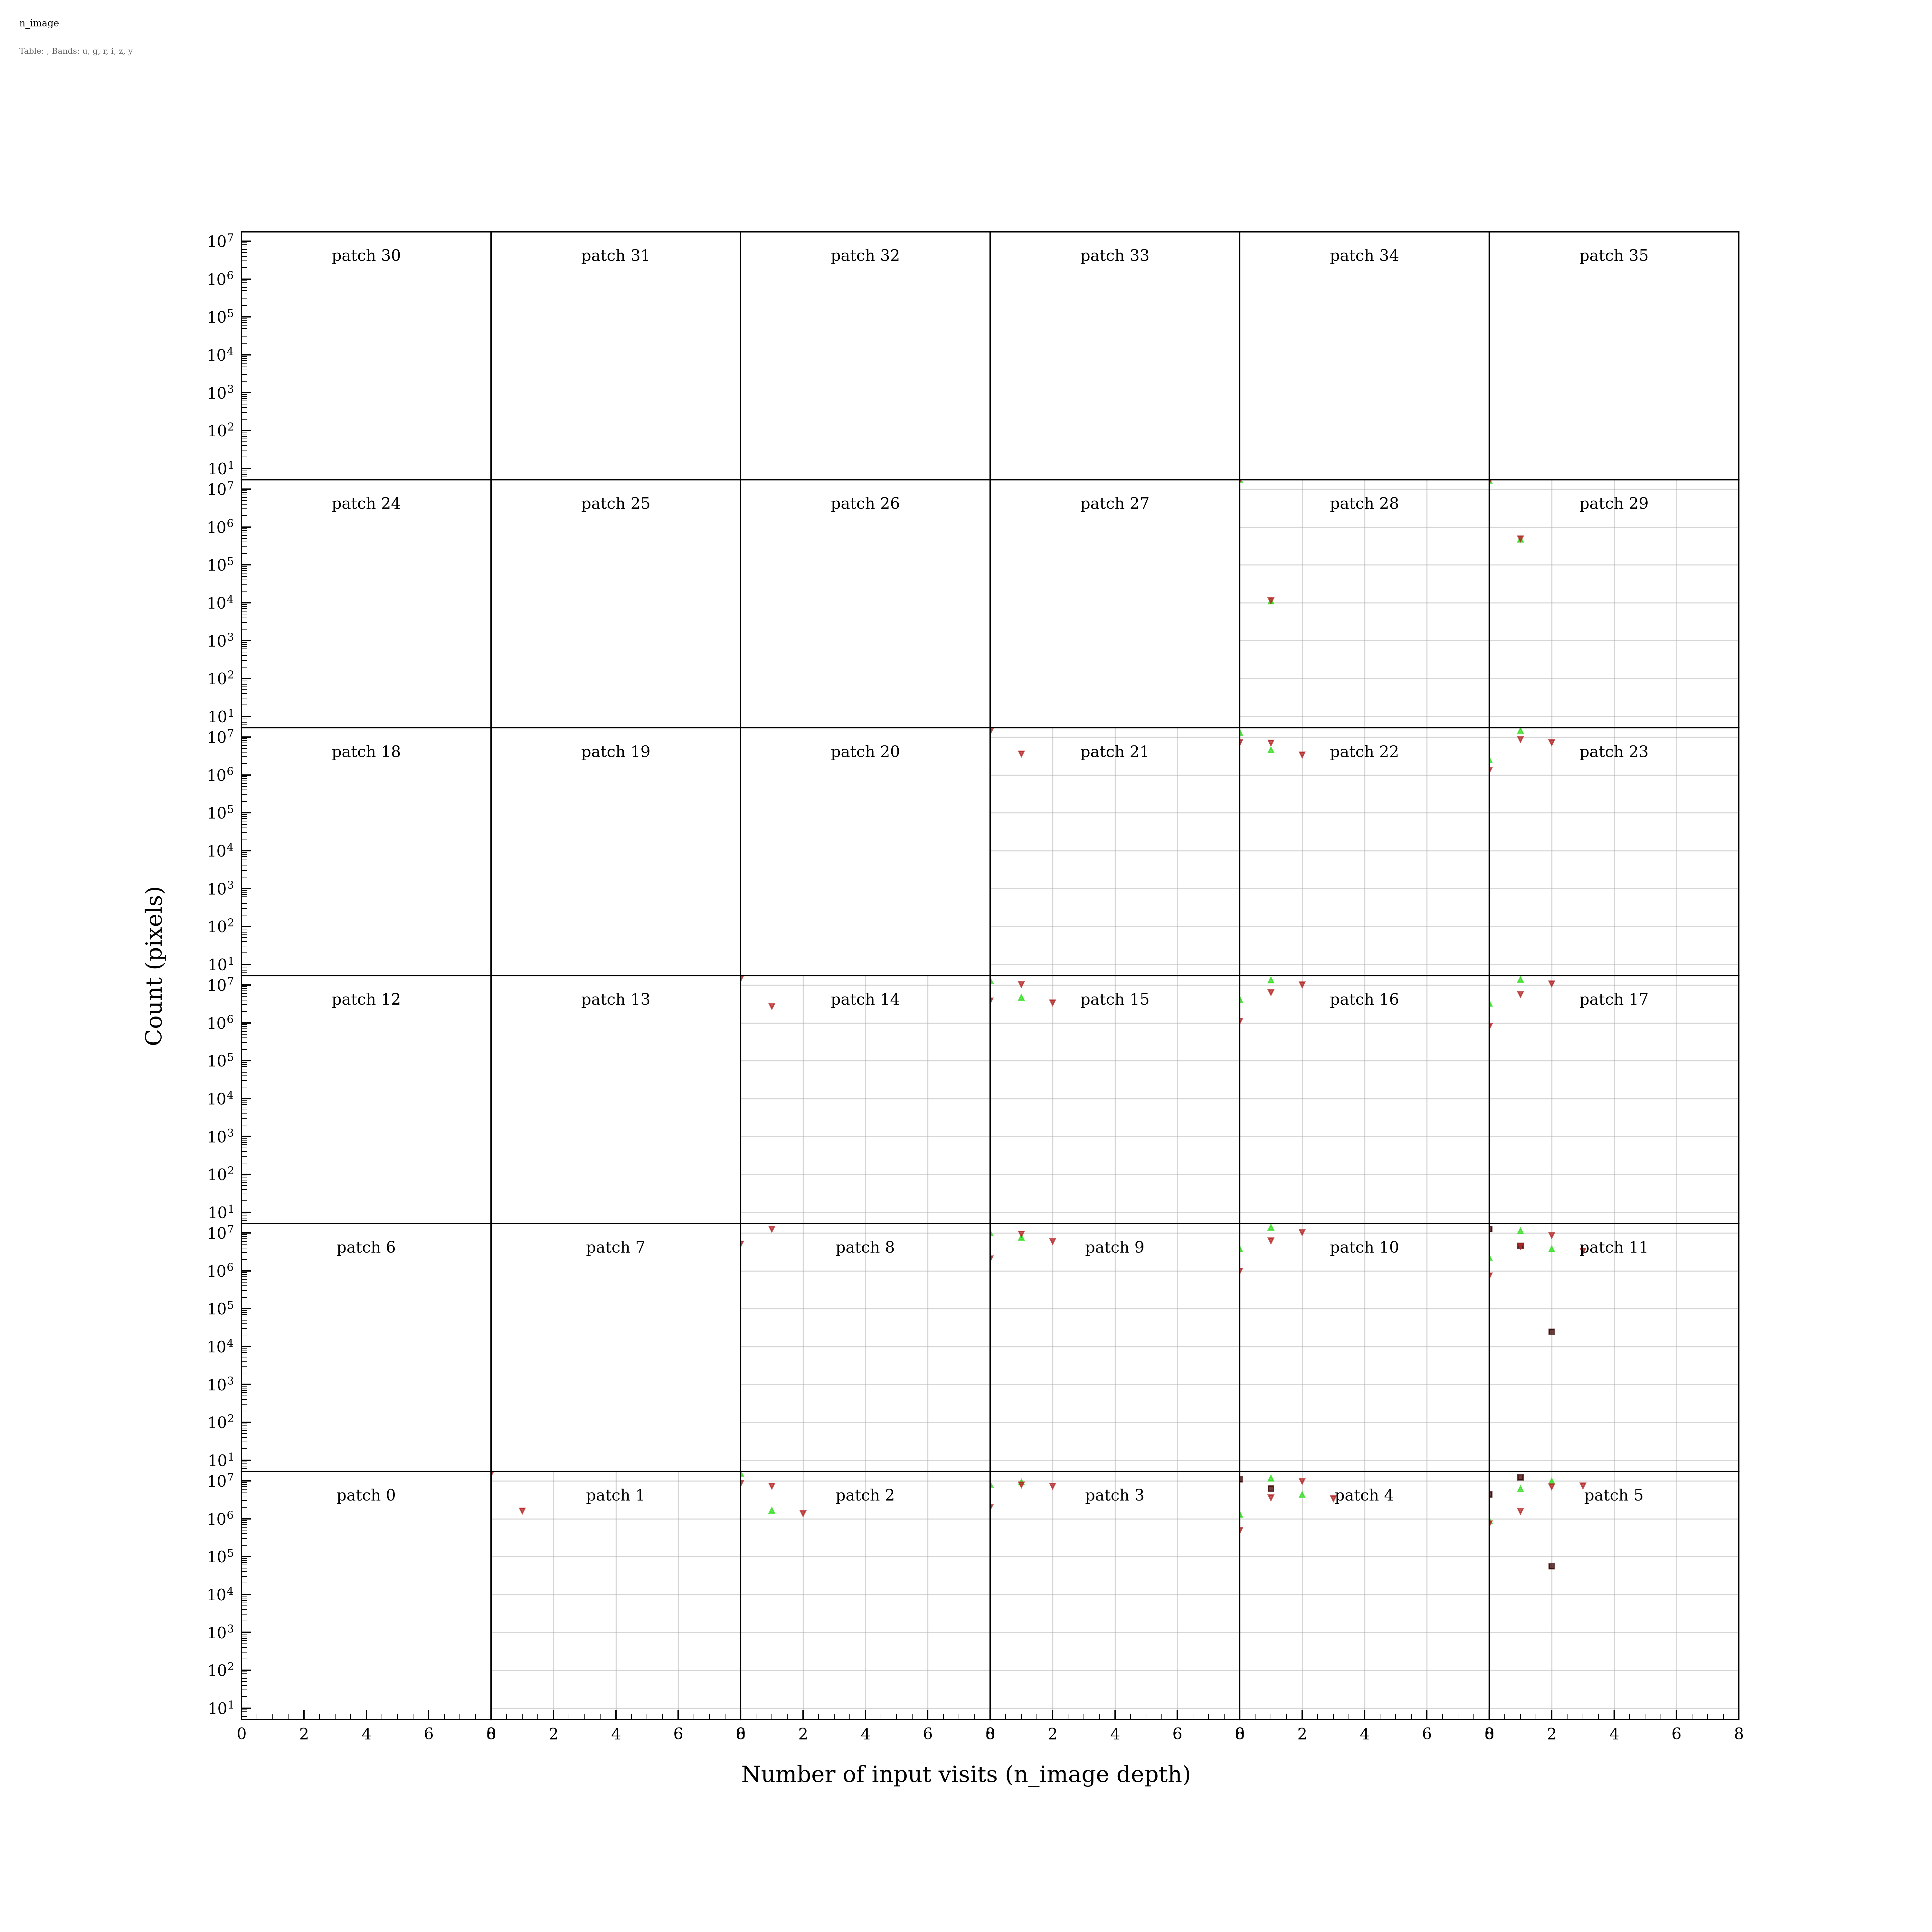

**tract 6939**

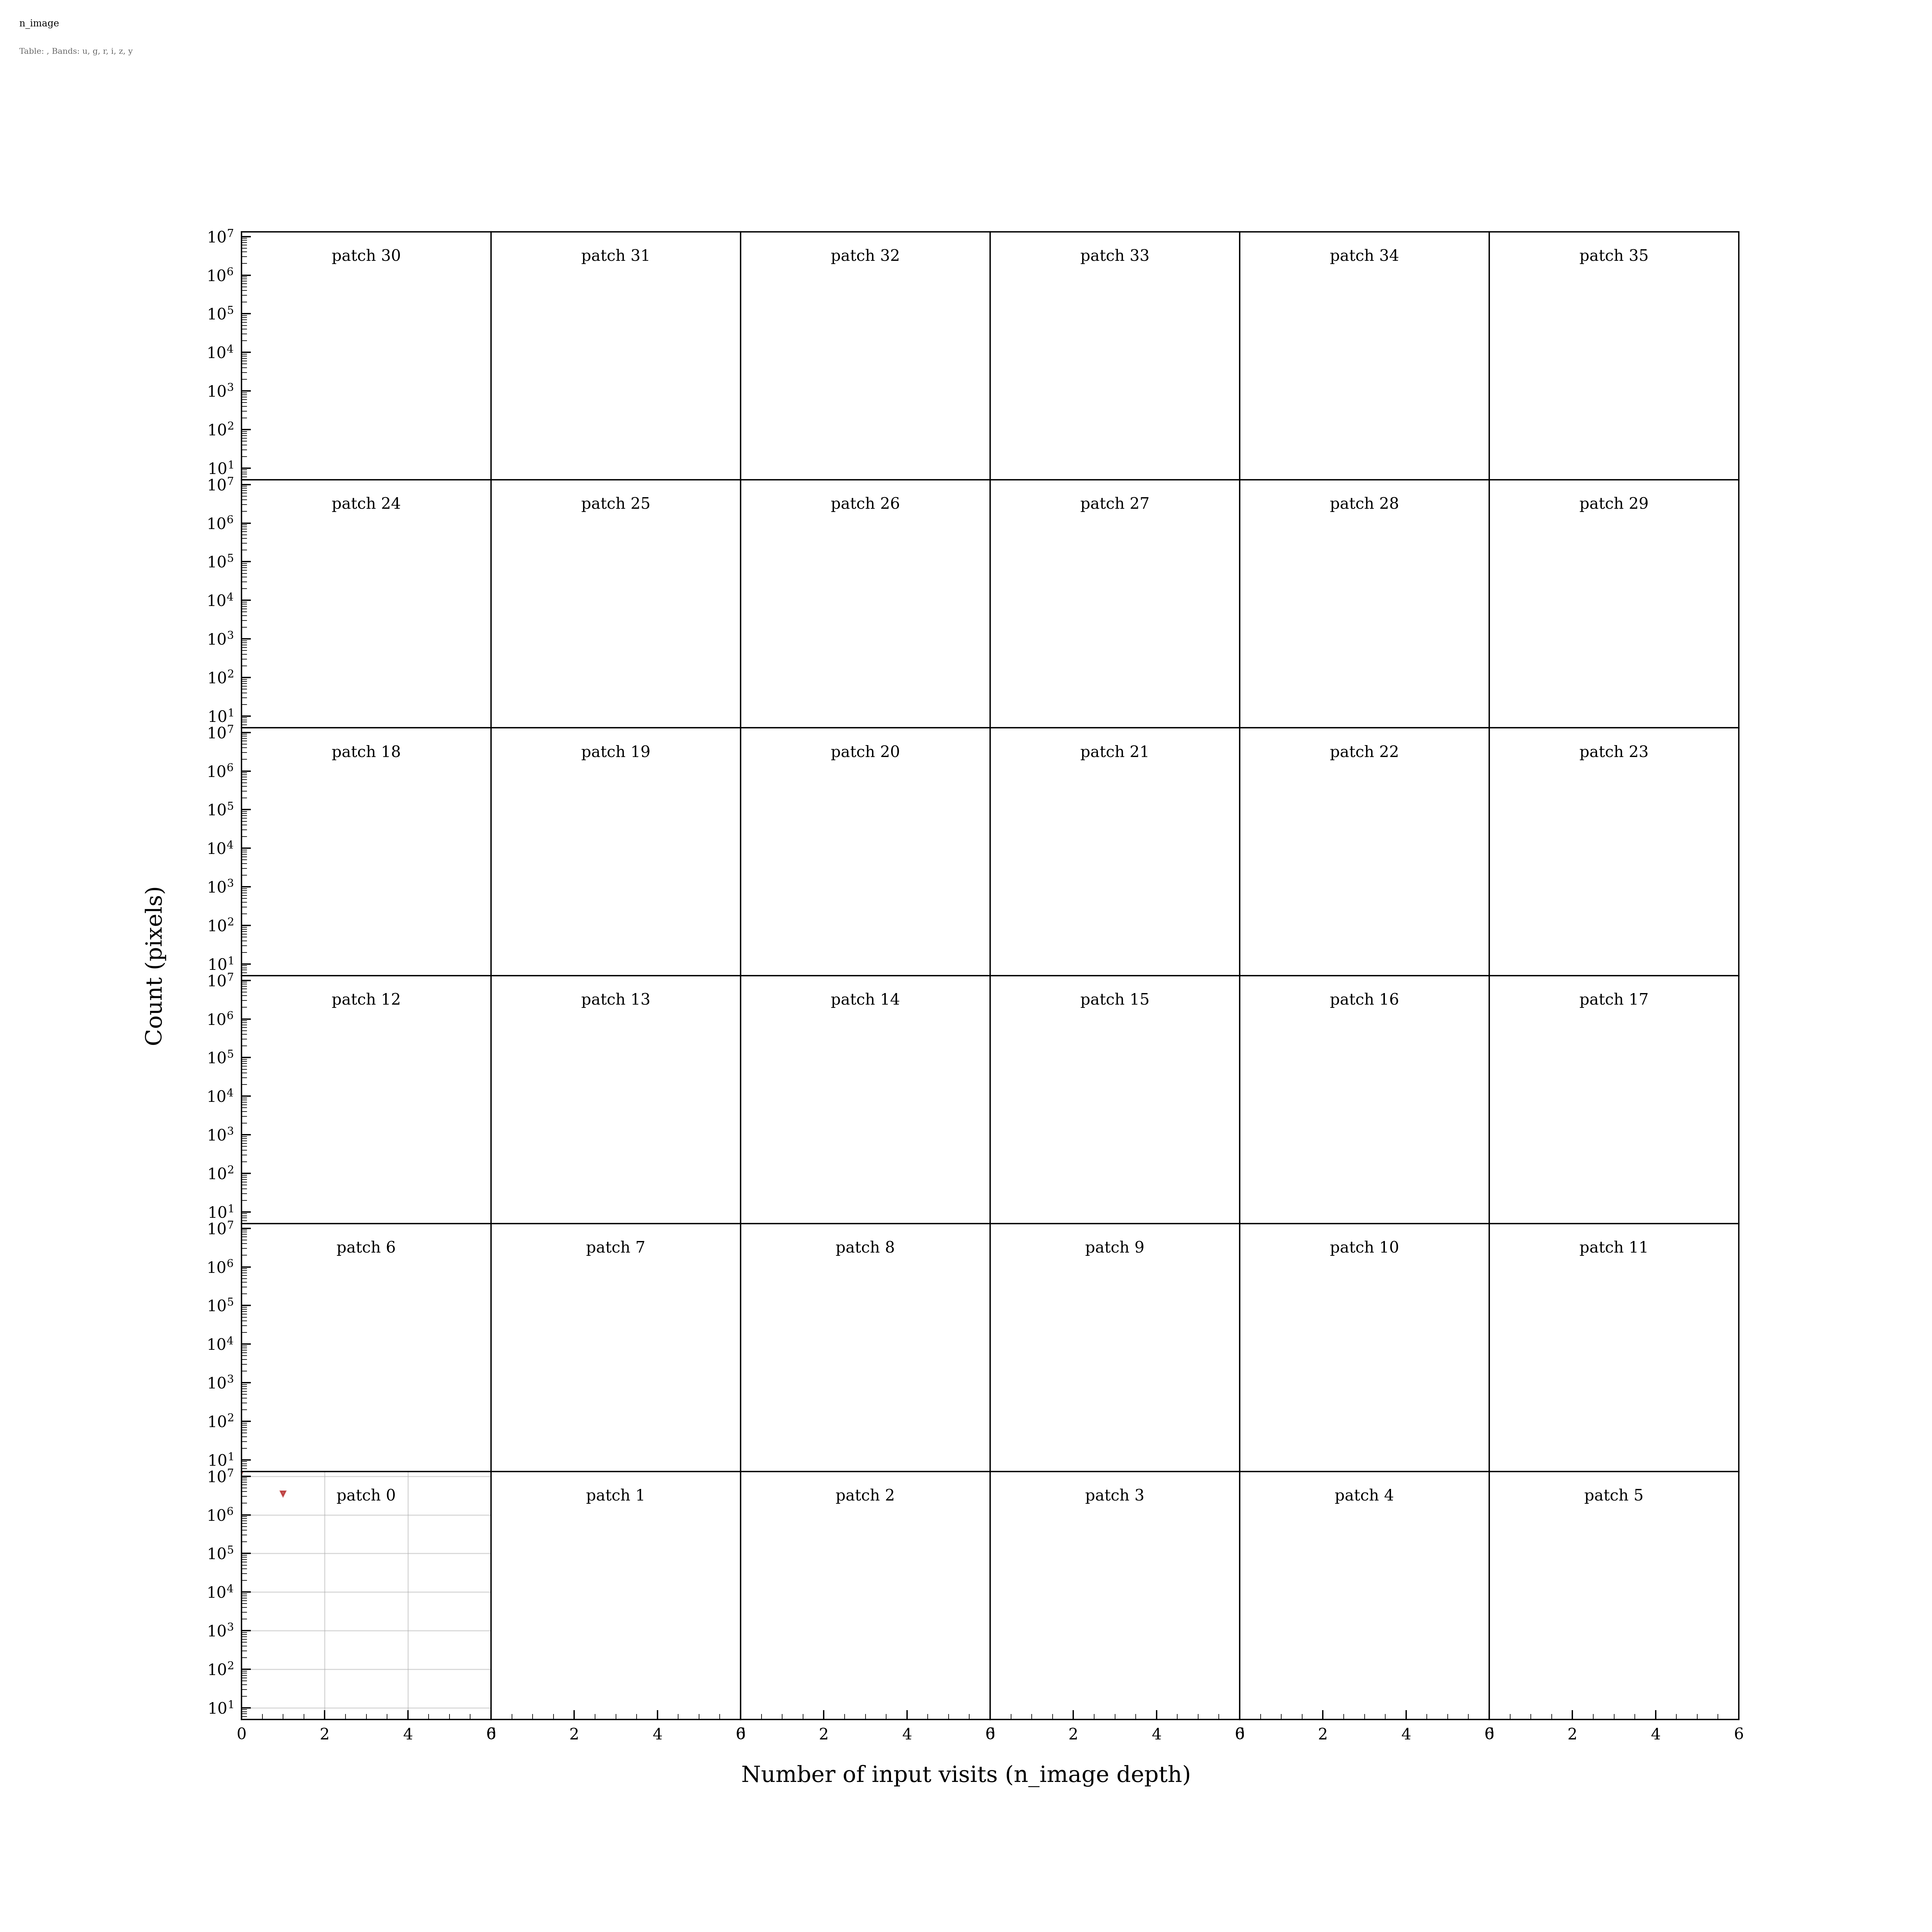

**tract 8349**

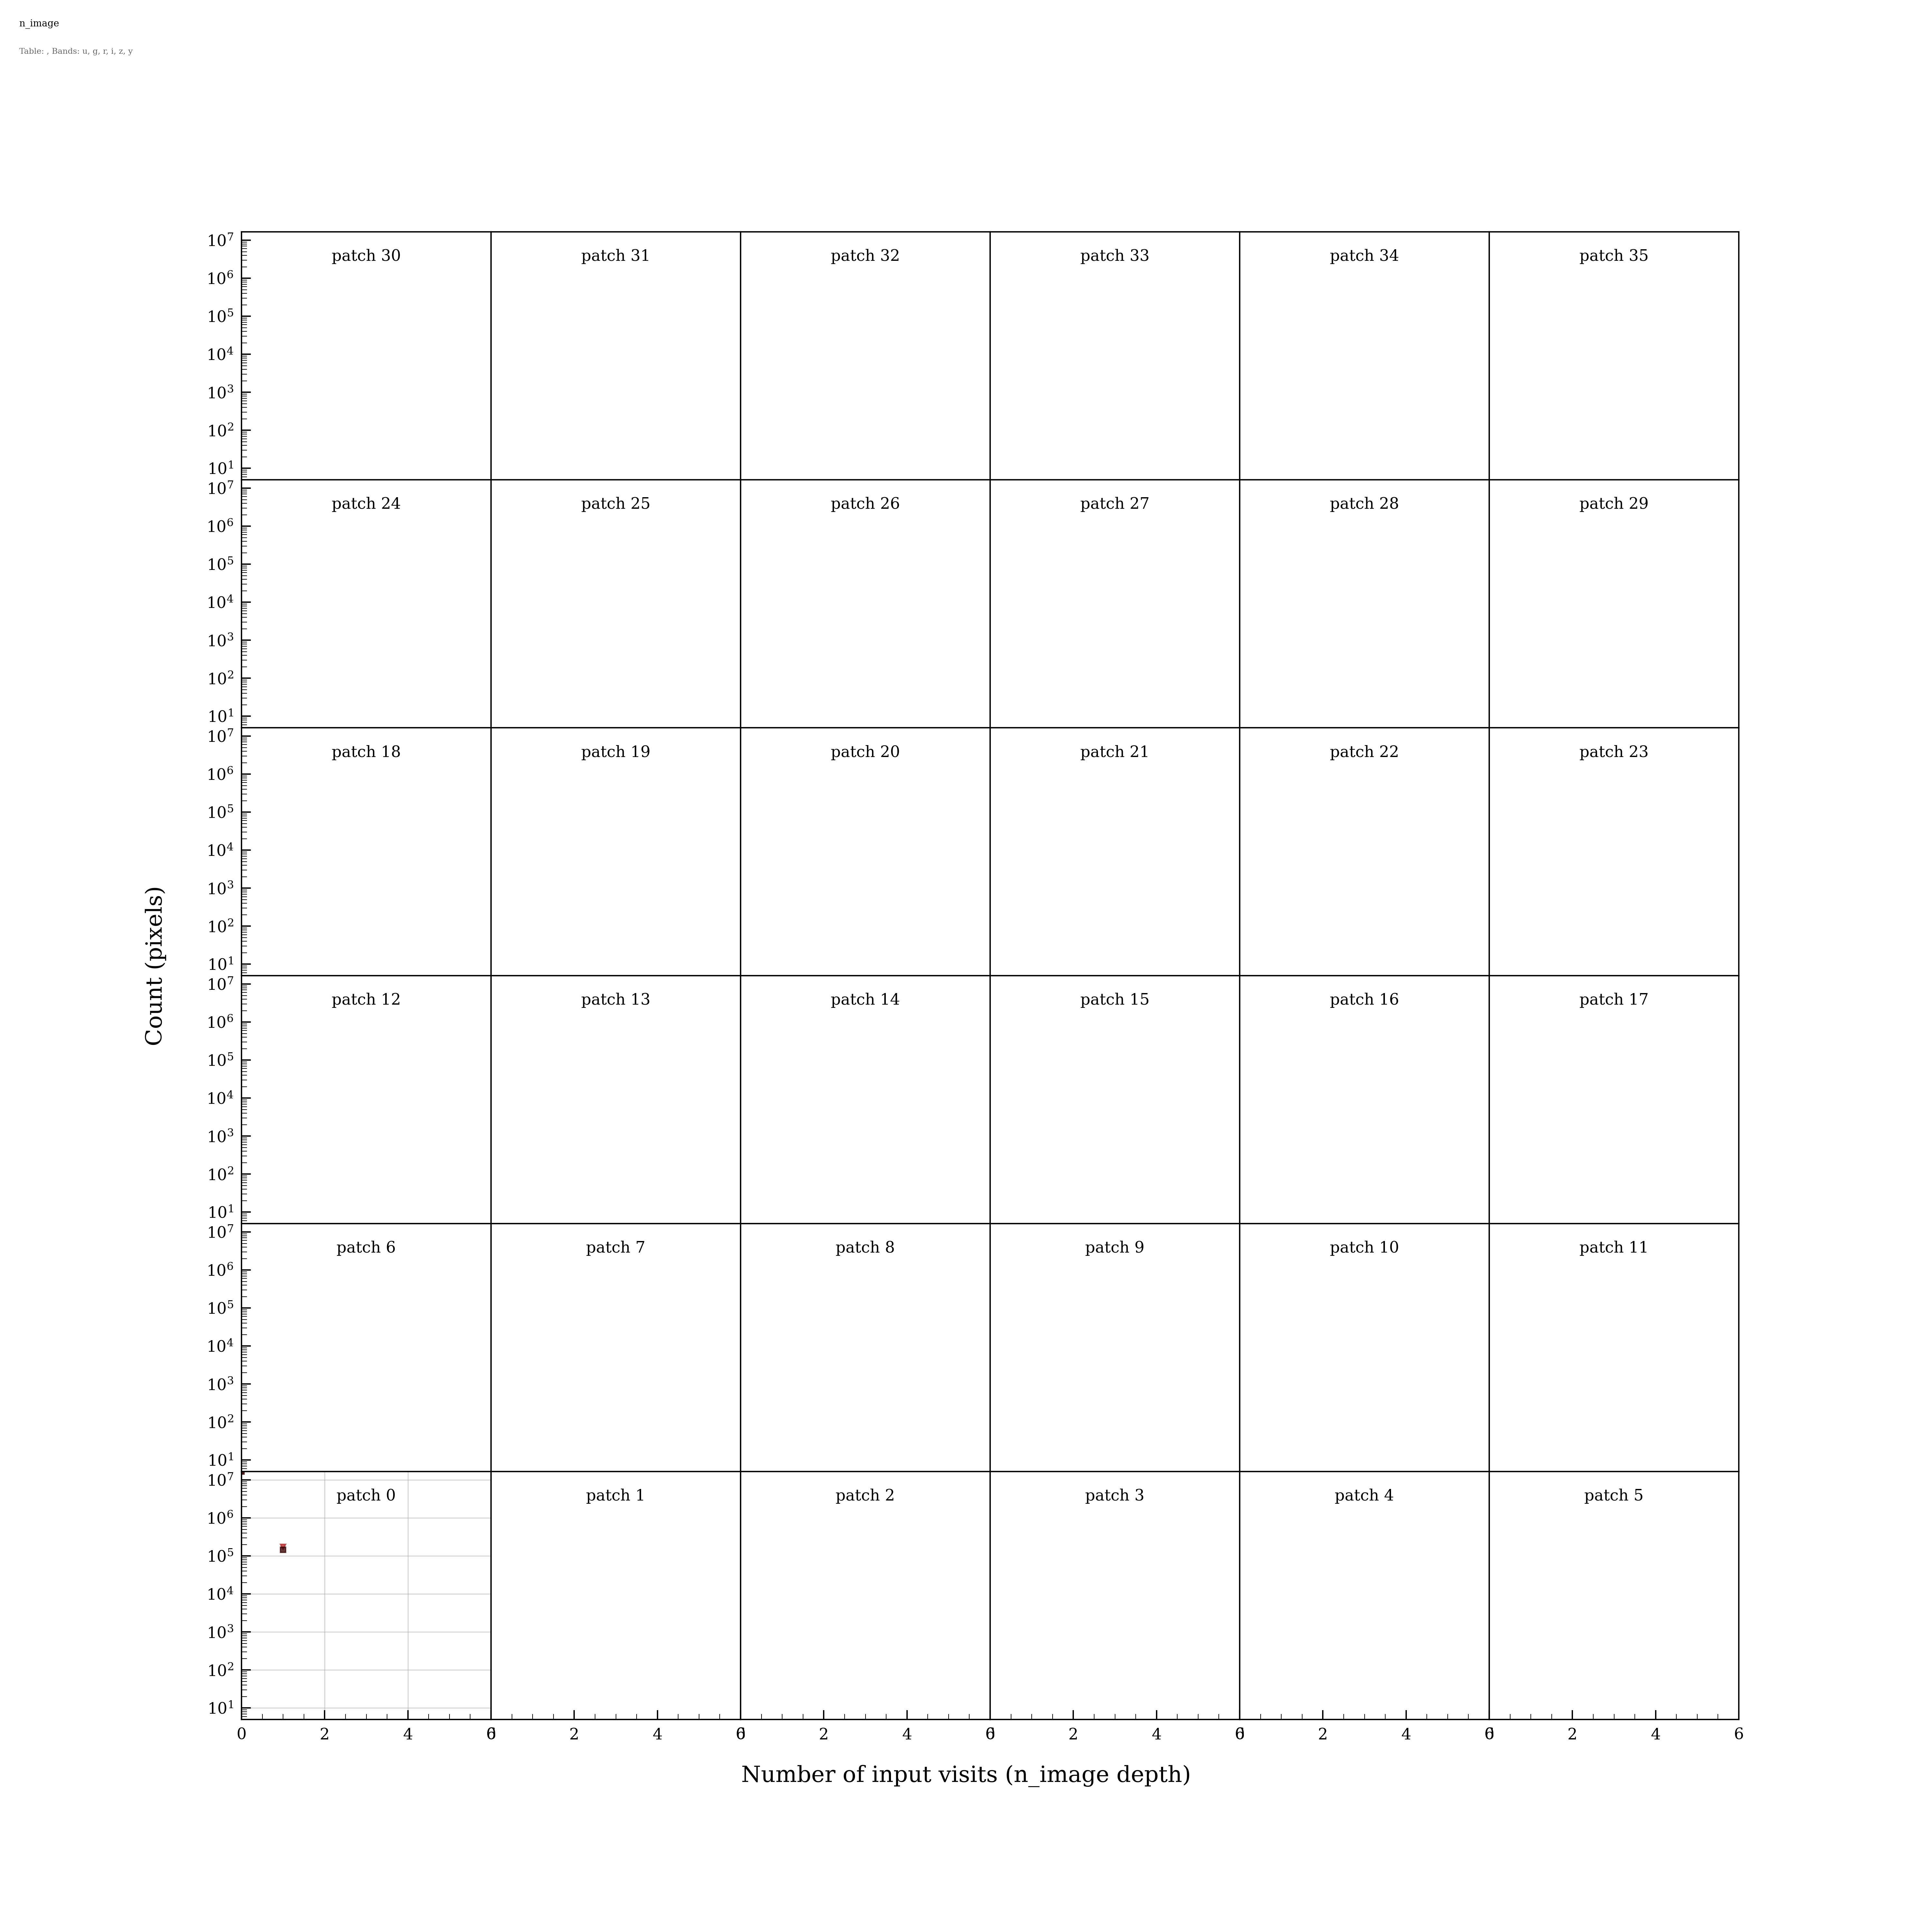

**tract 8116**

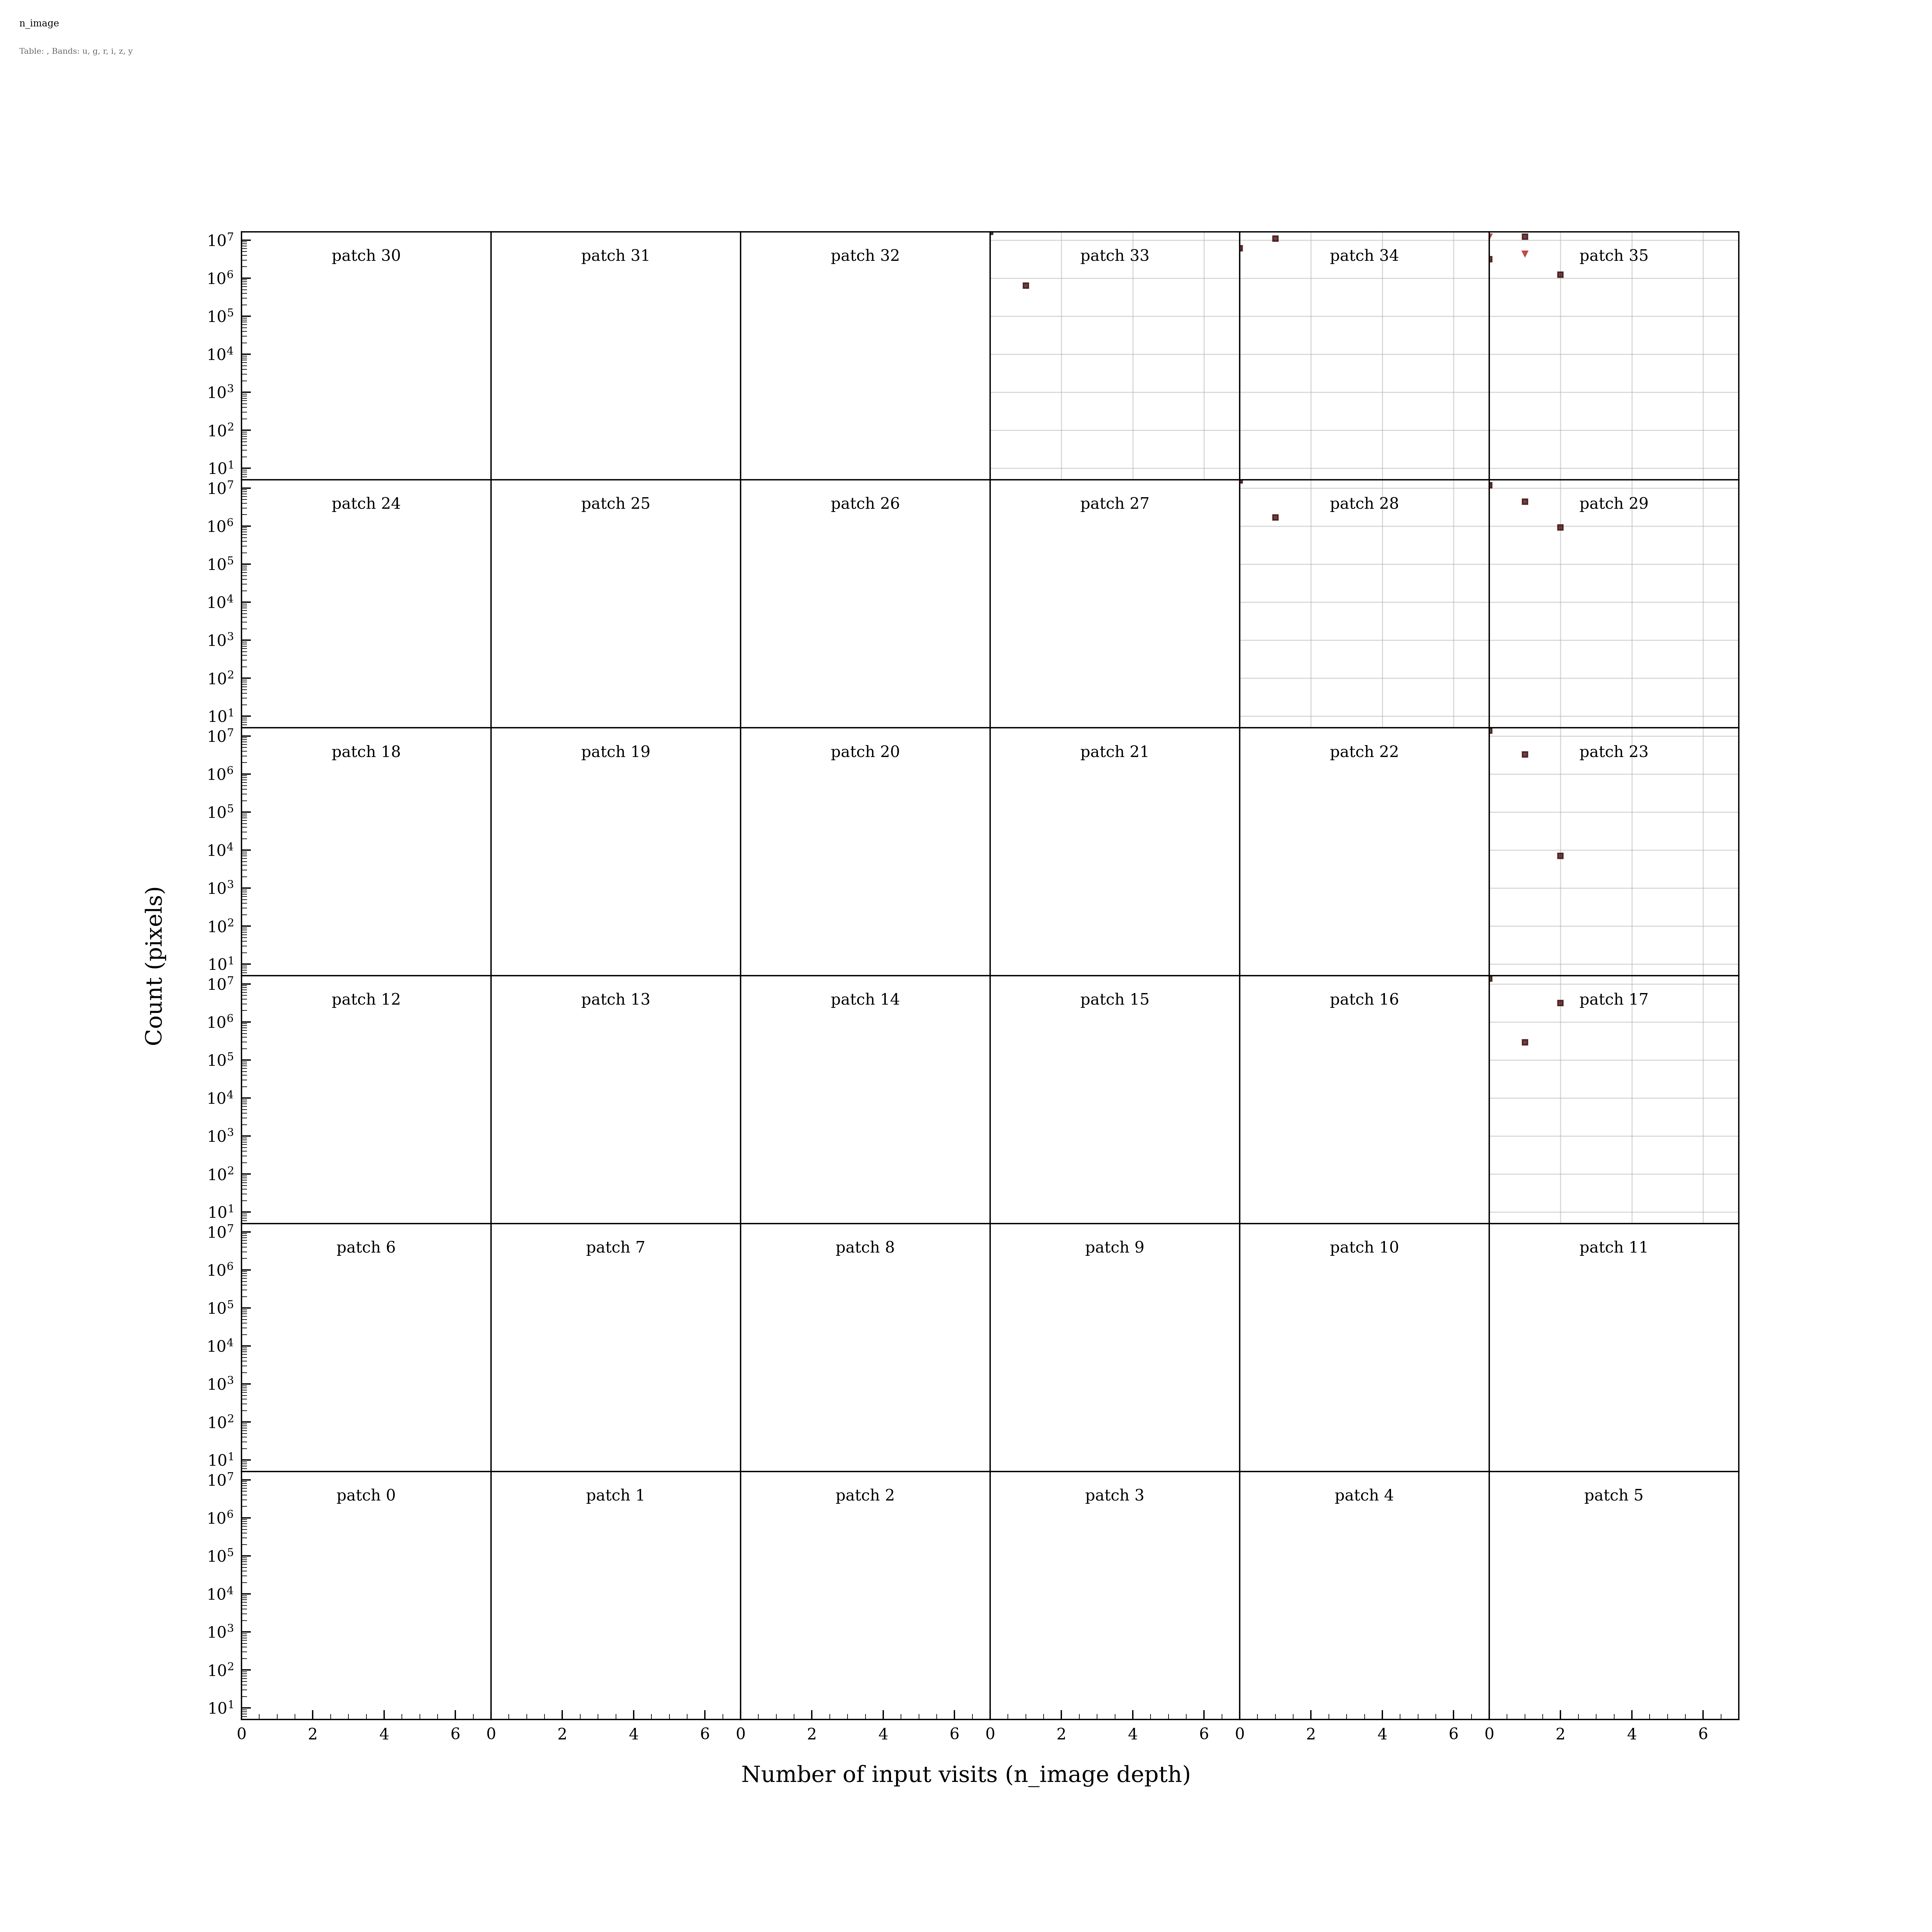

In [16]:
plot_refs = {r.dataId["tract"]: r for r in refs("coadd_depth_template_n_image_CoaddDepthPlot", ANALYSIS_RUN)}
print(f"{len(plot_refs)} depth plots in the RUN")
tracts = SHOW_DEPTH_PLOT_TRACTS or list(dict.fromkeys(shallow["tract"]))[:N_WORST]
for t in tracts:
    if t in plot_refs:
        display(Markdown(f"**tract {t}**"))
        show_png(plot_refs[t], width=900)
    else:
        print(f"tract {t}: no depth plot (not run yet, or no n_image for the selected bands)")

## 6. Coverage gaps and flagged tracts

Tracts with templates but missing QA, then one row per (band, tract) that fails a threshold
from the Parameters cell.

In [19]:
rows = []
for band in BANDS:
    t_all = tmpl[band]
    rows.append(dict(
        band=band, template_tracts=len(t_all),
        no_upstream_depth=len(t_all - set(upstream_depth.get(band, {}))),
        no_depth_row=len(t_all - set(depth.loc[depth["band"] == band, "tract"])),
        no_mask_row=len(t_all - set(mask.loc[mask["band"] == band, "tract"])) if len(mask) else len(t_all),
        no_depth_plot=len(t_all - set(plot_refs)),
    ))
gaps = pd.DataFrame(rows).set_index("band")
display(gaps)
for band in BANDS:
    missing = sorted(tmpl[band] - set(upstream_depth.get(band, {})))
    if missing:
        print(f"{band}: tracts with templates but no upstream tract QA ({len(missing)}): {missing[:60]}"
              + (" ..." if len(missing) > 60 else ""))

,template_tracts,no_upstream_depth,no_depth_row,no_mask_row,no_depth_plot
band,,,,,
g,586,44,44,44,0
r,751,42,42,42,0
i,938,0,0,0,0


g: tracts with templates but no upstream tract QA (44): [152, 153, 247, 248, 255, 314, 377, 378, 381, 451, 2105, 2258, 2404, 2420, 2570, 2581, 3657, 3730, 3731, 3853, 4051, 4126, 4184, 4592, 4593, 4803, 4915, 5016, 5568, 5569, 5570, 5571, 5670, 5899, 5904, 5906, 6351, 6586, 6709, 6942, 7052, 7180, 7290, 7892]
r: tracts with templates but no upstream tract QA (42): [675, 1654, 2087, 2089, 2565, 2567, 2568, 2737, 3536, 3728, 3850, 4124, 4608, 4653, 5298, 5349, 5350, 5569, 5570, 5571, 5790, 5795, 6244, 6249, 6477, 6479, 6942, 7181, 7632, 8597, 9320, 9325, 9564, 10051, 10053, 10063, 10545, 10775, 11025, 11269, 11508, 11731]


In [20]:
flags = []
if len(depth):
    d = depth[depth["depth_above_threshold_1_mean"] < MIN_FRAC_DEPTH_GE_1]
    flags += [dict(band=b, tract=t, kind="low coverage", flag=f"n_image≥1 on {v:.0f}% < {MIN_FRAC_DEPTH_GE_1:.0f}%")
              for b, t, v in zip(d["band"], d["tract"], d["depth_above_threshold_1_mean"])]
if len(mask) and "NO_DATA" in MASK_COLS:
    m = mask[mask[MASK_COLS["NO_DATA"]] > MAX_NO_DATA_FRACTION]
    flags += [dict(band=b, tract=t, kind="NO_DATA", flag=f"NO_DATA {v:.2f} > {MAX_NO_DATA_FRACTION}")
              for b, t, v in zip(m["band"], m["tract"], m[MASK_COLS["NO_DATA"]])]
if len(interp):
    i = interp[interp["interp_fraction"] > MAX_INTERP_FRACTION]
    flags += [dict(band=b, tract=t, kind="interpolation", flag=f"patch {p}: interp {v:.3f} > {MAX_INTERP_FRACTION}")
              for b, t, p, v in zip(i["band"], i["tract"], i["patch"], i["interp_fraction"])]
flags = pd.DataFrame(flags, columns=["band", "tract", "kind", "flag"])
display(flags.groupby(["kind", "band"]).size().unstack(fill_value=0)
        .style.set_caption("flags per kind and band (interpolation counts patches)"))
summary = flags.groupby(["band", "tract"])["flag"].apply("; ".join).reset_index()
display(Markdown(f"**{len(summary)} (band, tract) pairs flagged**"
                 + ("" if RUN_COMPLETE else ". The run is incomplete, so this is a lower bound.")))
display(summary.head(200))

band,g,i,r
kind,,,
NO_DATA,118,160,166
low coverage,114,144,147


**461 (band, tract) pairs flagged**

,band,tract,flag
0,g,114,n_image≥1 on 33% < 50%; NO_DATA 0.68 > 0.5
1,g,195,n_image≥1 on 3% < 50%; NO_DATA 0.97 > 0.5
2,g,204,n_image≥1 on 26% < 50%; NO_DATA 0.74 > 0.5
3,g,246,n_image≥1 on 1% < 50%; NO_DATA 1.00 > 0.5
4,g,256,n_image≥1 on 50% < 50%; NO_DATA 0.52 > 0.5
...,...,...,...
195,i,4382,n_image≥1 on 49% < 50%; NO_DATA 0.55 > 0.5
196,i,4390,n_image≥1 on 49% < 50%; NO_DATA 0.54 > 0.5
197,i,4391,n_image≥1 on 5% < 50%; NO_DATA 0.95 > 0.5
198,i,4457,n_image≥1 on 33% < 50%; NO_DATA 0.69 > 0.5
